# **Загрузка библиотек и датасета**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from scipy import stats
import gdown

id = "1shMHtWma_I8VoCl7X7kHbHFfiw68cHJq"
url = f"https://drive.google.com/uc?id={id}"
gdown.download(url, "winequality-white.csv", quiet=False)
wine_quality = pd.read_csv("winequality-white.csv", sep=';')


Downloading...
From: https://drive.google.com/uc?id=1shMHtWma_I8VoCl7X7kHbHFfiw68cHJq
To: /content/winequality-white.csv
100%|██████████| 264k/264k [00:00<00:00, 7.30MB/s]


# **I. Обоснование стохастической природы данных**

Для выполнения лабораторной работы мы выбрали три случайные величины: ***residual_sugar***(остаточный сахар), ***density***(плотность) и ***pH***(кислотность).

Значение каждой из выбранных величин случайно, так как зависит от множества неконтролируемых факторов: кол-во осадков и солнечных дней, температура, состав почвы на конкретном участке виноградника, метаболизм микроорганизмов, взаимодействие компонентов и т.д.. Попробуем подтвердить это с помощью статистики.

## **1. residual_sugar**

###**Природа события**

**Остаточный сахар** - это кол-во сахара, оставшееся после остановки процесса ферментации(брожения).

**Причины случайности:**

*   *Брожение*. Точный момент, когда дрожжи «уснут», погибнут или сахара исчерпаются, зависит от микроусловий в каждой конкретной бочке или бутылке.
*   *Человеческий фактор и погрешность*. Винодел может стремиться сделать сухое или полусладкое вино, но технологический процесс не идеален. Температурные колебания в чане на доли градуса создают случайное отклонение конечного результата.

### **Анализ распределения**

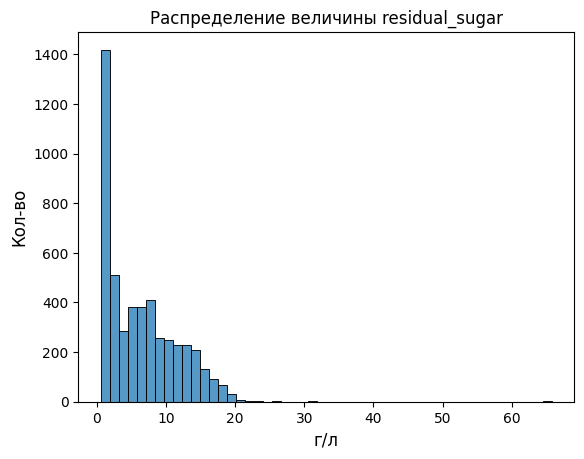

In [ ]:
residual_sugar = wine_quality["residual sugar"]
def plot_hist(data, bins, xlabel, ylabel, title, log_scale=None, kde=None):
  ax = sns.histplot(data, bins=bins, log_scale=log_scale, kde=kde)
  ax.set_xlabel(xlabel, fontsize=12)
  ax.set_ylabel(ylabel, fontsize=12)
  ax.set_title(title)
  plt.show()

plot_hist(residual_sugar, 50, 'г/л', 'Кол-во', 'Распределение величины residual_sugar')

**Замечания:**

* На графике видно, что распределение  имеет ярко
выраженную асимметрию. Пик находится очень близко к нулю (около 1-2 г/л). Это закономерно, ведь дрожжи стремяться переработать весь сахар, а residual_sugar не может быть меньше 0.
* Длинный хвост уходит вправо до значений 30-66 г/л. Скорее всего для описания данных лучшим образом подойдёт медиана, а не среднее значение.  
* Гистограмма говорит о том, что residual_sugar не «классическая» случайная величина с нормальным распределением. Большинство вин имеют очень низкое содержание остаточного сахара, но есть небольшая группа вин с очень высоким содержанием.


**Статистики**

In [ ]:
s = residual_sugar
print("Количество:", s.count())
print("Среднее:", s.mean())
print("Медиана:", s.median())
print("Минимум:", s.min())
print("Максимум:", s.max())
print("Стандартное отклонение:", s.std())
print("Дисперсия:", s.var())
print("95-й перцентиль:", s.quantile(0.95))

Количество: 4898
Среднее: 6.391414863209474
Медиана: 5.2
Минимум: 0.6
Максимум: 65.8
Стандартное отклонение: 5.072057784014864
Дисперсия: 25.725770164385768
95-й перцентиль: 15.7


**Замечания:**
* Среднее (6.39) заметно больше медианы (5.2).
Максимум (65.8) находится невероятно далеко от среднего и медианы, учитывая, что 95% всех вин имеют показатель сахара ниже 15.7. Значит несколько очень сладких вин сильно «тянут» среднее арифметическое значение вверх. Медиана (5.2) в данном случае гораздо лучше отражает типичное вино из этого датасета, чем среднее.

* СКО довольно велико: 5.07 при среднем 6.39, что говорит о высоком разбросе данных. Коэффициент вариации (отношение стандартного отклонения к среднему) составляет около 80%. Возможно это объясняется тем, что в датасете смешаны сухие и сладкие вина.

* Max(65.8) и min(0.6) значения residual_sugar отличаются на 2 порядка. Попробуем использовать логарифмическую шкалу, чтобы увидеть бимодальность распределения.

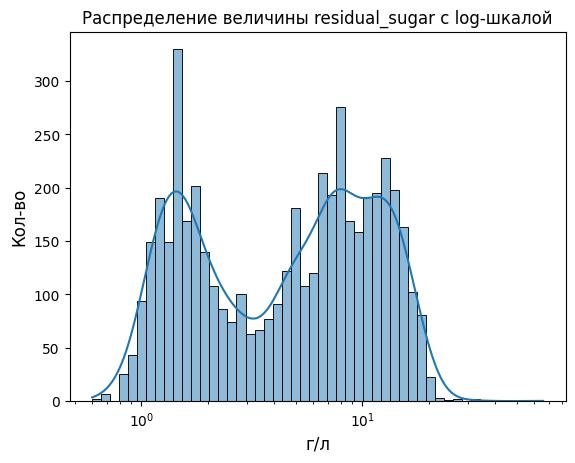

In [ ]:
plot_hist(residual_sugar, 50, 'г/л', 'Кол-во', 'Распределение величины residual_sugar с log-шкалой', log_scale=True, kde=True)

**Замечания:**
* Логарифмирование растягивает область малых значений и сжимает большие. Это позволяет увидеть то, что не видно на обычном графике.

* На лог-шкале отчетливо заметна бимодальность. Это означает, что в датасете, скорее всего, смешаны два разных типа вин: сухие и полусухие или полусладкие.
* Виноделы намеренно останавливают брожение или добавляют сахар, чтобы получить определенный вкус, поэтому данные концентрируются вокруг определенных стандартов производства,

### **Вывод**


* Показатель residual_sugar можно рассматривать как случайную величину, так как при случайном выборе образца вина её конкретное значение заранее неизвестно и зависит от множества факторов, связанных с технологией производства и ферментации. Однако, её распределение не является нормальным и характеризуется значительным разбросом и правой асимметрией.
* В дальнейшем для анализа данной величины лучше разбить данные на две категории(сухие и полусухие или полусладкие вина) либо использовать log(residual_sugar)



## **2. density**

###**Природа события**

**Плотность** — это масса вещества, приходящаяся на единицу его объема.

**Причины случайности:**
* *Зависимость от концентрации сахара*.
Сахар тяжелее воды. Чем больше в вине осталось недобродившего сахара(случайная величина), тем выше его плотность.
* Зависимость от содержания алкоголя.
В процессе брожения сахар превращается в спирт, который легче воды. А кол-во образующегося спирта в каждой бутылке случайно (зависит от активности дрожжей, температуры брожения).
* *Зависимость от экстрактивных веществ и кислот*.
Колебания массы растворенных минералов, глицерина, органических кислот влияют на массу жидкости в объеме.
* *Температура*. Плотность жидкости напрямую зависит от температуры (при нагревании жидкость расширяется, и ее плотность падает). В свою очередь температура окружающей среды в момент измерения или хранения бутылки подвержена случайным колебаниям.

### **Анализ распределения**

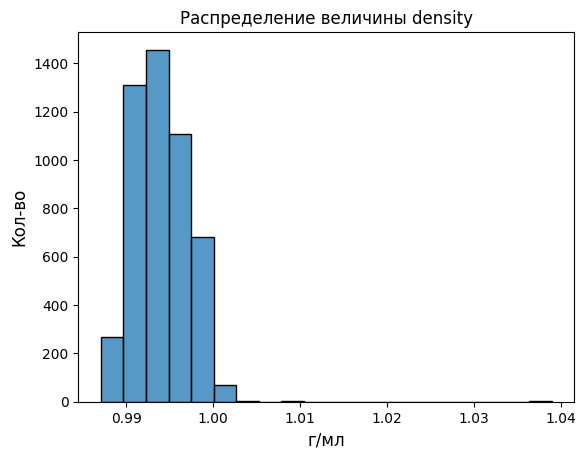

In [ ]:
density = wine_quality["density"]
plot_hist(density, 20, 'г/мл', 'Кол-во', 'Распределение величины density')

**Замечания:**

*  Гистограмма показывает, что основная масса значений сосредоточена слева около 0.99. Значит, плотность почти всех вин в выборке крайне близка к плотности чистой воды (1.0 г/мл), которая является основным по объёму компонентом вина.
* Заметен длинный "хвост" вправо, уходящий к значениям 1.01 и даже 1.04. Скорее всего медиана будет более устойчивым показателем центра в данном случае, так как на среднее влияют редкие, но высокие выбросы.

**Статистики**

In [ ]:
s = density
print("Количество:", s.count())
print("Среднее:", s.mean())
print("Медиана:", s.median())
print("Минимум:", s.min())
print("Максимум:", s.max())
print("Стандартное отклонение:", s.std())
print("Дисперсия:", s.var())
print("95-й перцентиль:", s.quantile(0.95))

Количество: 4898
Среднее: 0.9940273764801959
Медиана: 0.99374
Минимум: 0.98711
Максимум: 1.03898
Стандартное отклонение: 0.0029909069169369354
Дисперсия: 8.945524185781203e-06
95-й перцентиль: 0.999


**Замечания:**

* *Очень низкие СКО (0.003) и дисперсия (8.95e-06)*. Это означает, что 95% всех вин имеют плотность в очень узком диапазоне: от 0.987 до 0.999 (согласно 95-му перцентилю). Именно поэтому гистограмма выглядит "узкой". Масштаб оси X растянут из-за выбросов до 1.04. Попробуем убрать эти выбросы и посмотреть на распределение.


**Очистка от выбросов методом IQR**

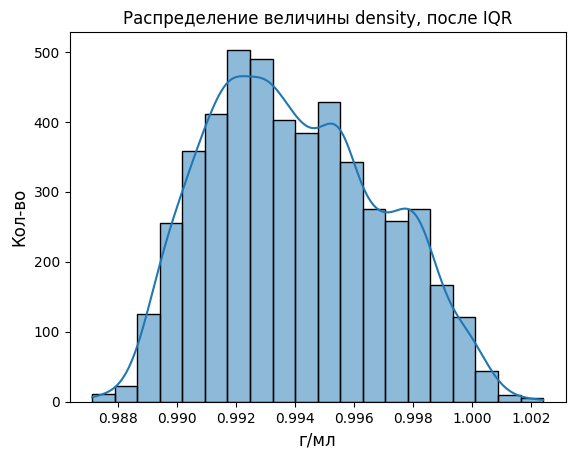

In [ ]:
def iqr_bounds(data, k=1.5):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    return Q1 - k * IQR, Q3 + k * IQR

    return data[(data >= lower_bound) & (data <= upper_bound)]

def filter_iqr(data, k=1.5):
    lo, hi = iqr_bounds(data, k)
    return data[(data >= lo) & (data <= hi)]

density_clean_iqr = filter_iqr(wine_quality['density'])

plot_hist(density_clean_iqr, 20, 'г/мл', 'Кол-во', 'Распределение величины density, после IQR', kde=True)


**Замечания:**

* После очистки выбросов распределение стало гораздо более симметричным и приближенным к нормальному (хотя и не идеальным "колоколом").
* *Мультимодальность*. Теперь на графике явно просматриваются два основных пика (около 0.993 и 0.995). Скорее всего, в датасете смешаны вина разных типов, в частности это может быть связано с разным содержанием остаточного сахара, которое было рассмотрено в предыдущем пункте.

### **Вывод**

* Величину density можно считать случайной, так как она принимает различные числовые значения в определённом диапазоне,  образуя статистическое распределение с выраженным средним значением и ненулевой дисперсией. Наличие этого разброса и невозможность предсказать точное значение плотности для конкретного вина без дополнительных данных говорит о её вероятностной природе.

* Также в пользу случайности говорит то, что в датасете не учтены такие важные для плотности показатели как температура, содержание алкоголя и экстрактивных веществ, стохастичность биологических процессов и человеческий фактор.

**Итог:** Так как мы не можем проконтролировать все эти физико-химические и человеческие факторы(погрешности приборов, опечатки), влияющие на результат, мы будем считать данную величину случайной.

## **3. pH**

###**Природа события**

**pH** - мера активности ионов водорода в растворе, показывающая степень кислотности или щелочности.

**Причины случайности:**
* *Зависимость от других случайных величин.*
Химически pH является следствием концентрации различных кислот и солей в вине. Поскольку кислоты сами по себе случайны, их совокупный эффект (pH) также математически является случайной величиной.
* *Буферная система*. Взаимодействие десятков химических компонентов носит вероятностный характер в равновесие химических реакций.


### **Анализ распределения**

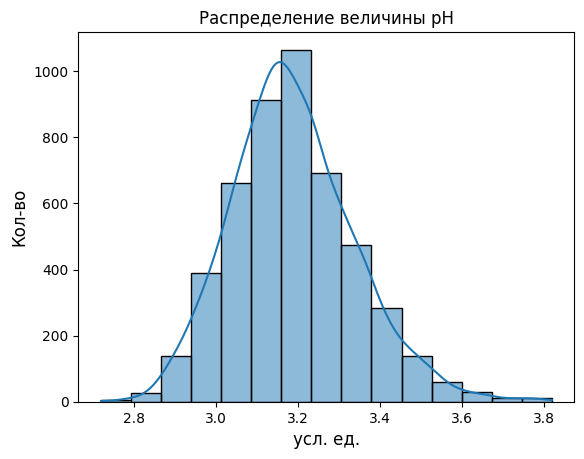

In [ ]:
pH = wine_quality["pH"]
plot_hist(pH, 15, 'усл. ед.', 'Кол-во', 'Распределение величины pH', kde=True)

**Замечания:**
* Несмотря на незначительную ассиметрию распределение величины pH достаточно близко к нормальному, что говорит в пользу её случайности

**Статистики**

In [ ]:
s = pH
print("Количество:", s.count())
print("Среднее:", s.mean())
print("Медиана:", s.median())
print("Минимум:", s.min())
print("Максимум:", s.max())
print("Стандартное отклонение:", s.std())
print("Дисперсия:", s.var())
print("95-й перцентиль:", s.quantile(0.95))

Количество: 4898
Среднее: 3.1882666394446715
Медиана: 3.18
Минимум: 2.72
Максимум: 3.82
Стандартное отклонение: 0.1510005996150667
Дисперсия: 0.02280118108410968
95-й перцентиль: 3.46


**Замечания:**
* Среднее значение pH (3.19) и медиана (3.18) практически равны, что говорит о симметричности основной массы данных.
* Дисперсия (0.023) очень низкая, что говорит о высокой плотности данных вокруг среднего значения и небольшой степени разброса.

### **Вывод**

Аргументы в пользу случайности pH:
* *Соответствие нормальному закону*. Форма гистограммы близка к классической
"колоколообразной" кривой Гаусса. В природе и технике именно случайные процессы чаще всего приводят к нормальному распределению.
* Отсутствие явных аномалий. На графике нет "провалов", мультимодальности или резких скачков.
* Совпадение среднего и медианы. Это признак того, что данные не смещены искусственно, а формируются под воздействием случайных симметричных колебаний.

**Итог:** Учитывая все приведённые факты, величину pH в данном датасете можно считать случайной.


# **II. Независимость величин**

## **Диаграммы рассеяния**

Начнём оценку зависимости величин с построения для них диаграмм рассеяния.  Если точки выстраиваются в линию или кривую — есть зависимость. Если это облако точек — зависимости нет.

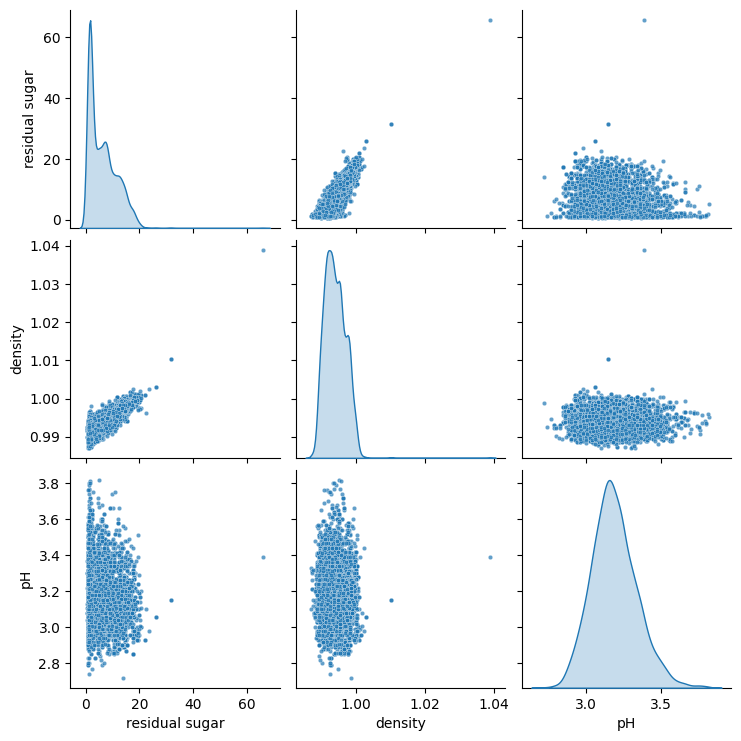

In [ ]:
cols = ['residual sugar', 'density', 'pH']
sns.pairplot(wine_quality[cols], diag_kind='kde', plot_kws={'alpha': 0.7, 's': 10})
plt.show()

**Замечания:**

*  Видна четкая положительная корреляция между residual_sugar и density. Чем больше остаточного сахара, тем выше плотность, так как сахар тяжелее воды.
* Диаграммы рассеяния для остальных пар величин представляют собой облака точек. Значит, скорее всего, между ними связь слабая либо отсутсвует.

## **Distance correlation**

Проверим наши догадки рассчитав **Distance Correlation** - статистический метод, который измеряет общую зависимость (как линейную, так и нелинейную) между двумя случайными величинами или векторами произвольной размерности.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [dcor]


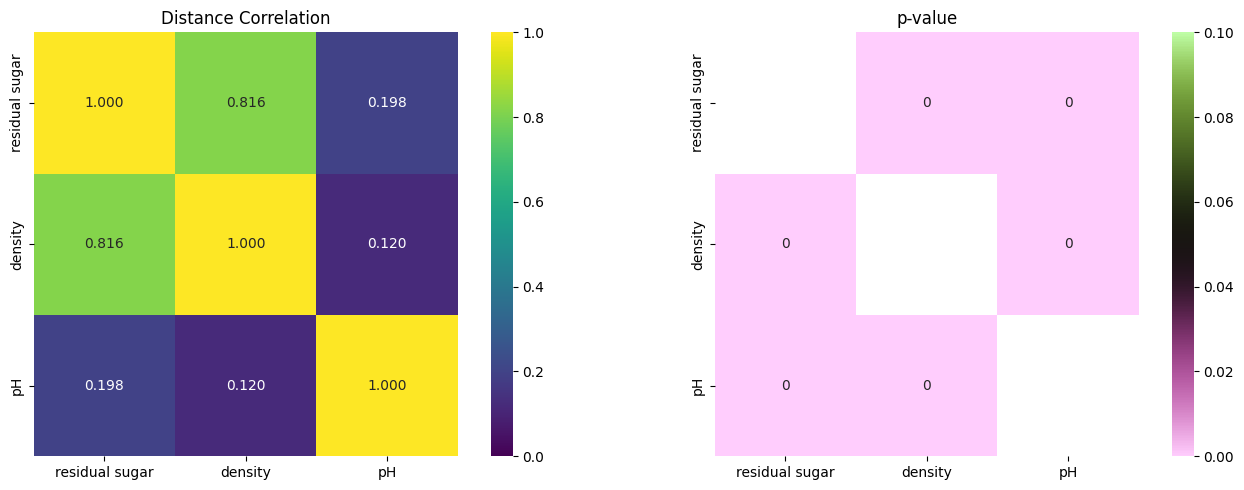

In [ ]:
!pip install dcor
import dcor

# IQR bounds
lo_rs, hi_rs = iqr_bounds(residual_sugar)
lo_d,  hi_d  = iqr_bounds(density)

# IQR filter
mask = (
    residual_sugar.between(lo_rs, hi_rs) &
    density.between(lo_d,  hi_d)
)
data_for_dc = wine_quality.loc[mask, ['residual sugar', 'density', 'pH']].dropna()

# dCor and p-value
cols = data_for_dc.columns.tolist()
n = len(cols)

dc_mat = np.ones((n, n))
pv_mat = np.full((n, n), np.nan)

for i in range(n):
    for j in range(i + 1, n):
        x = data_for_dc[cols[i]].values
        y = data_for_dc[cols[j]].values

        dc_mat[i, j] = dc_mat[j, i] = dcor.distance_correlation(x, y)
        pv_mat[i, j] = pv_mat[j, i] = dcor.independence.distance_correlation_t_test(x, y).pvalue

dc_df = pd.DataFrame(dc_mat, index=cols, columns=cols)
pv_df = pd.DataFrame(pv_mat, index=cols, columns=cols)

# heatmap
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distance Correlation
sns.heatmap(dc_df, annot=True, fmt='.3f', cmap='viridis',
            vmin=0, vmax=1, square=True, ax=axes[0])
axes[0].set_title('Distance Correlation')

# p-value
sns.heatmap(pv_df, annot=True, fmt='.3g', cmap='vanimo',
            vmin=0, vmax=0.1, square=True, ax=axes[1])
axes[1].set_title('p-value')

plt.tight_layout()
plt.show()

**Замечания:**

* *Статистическая значимость*. p-value для всех пар величин равен 0. Это говорит о том, что вероятность случайного получения такого результата dCor крайне мала.
* *Сильная положительная корреляция между величинами residual_sugar и density*. Значение Distance Correlation составляет 0.816. Можно утверждать, что между residual sugar и density существует выраженная сложная функциональная зависимост.
* *Независимость pH*. Ни с сахаром (0.198), ни с плотностью (0.120) он не показывает существенной связи.

## **Коэффициент корреляции Пирсона**

Проверим зависимость между величинами residual_sugar и density на линейность

In [ ]:
x = data_for_dc['residual sugar']
y = data_for_dc['density']
r, p_value = stats.pearsonr(x, y)
print(f"r = {r:.4f}, p = {p_value:.4f}")

r = 0.8315, p = 0.0000


**Замечания:**
* Достаточно большое значение коэффициента корреляции Пирсона (0.832) позволяет утверждать о наличии cильной прямо пропорциональной линейной зависимости между величинами residual_sugar и density. Этот факт согласуется с полученной ранее диаграммой рассеяния для этих величин.
* Корреляция статистически значима, так как p < 0.05

## **Вывод**

* Величин residual_sugar и density являются зависимыми. О чём свидетельствует:
  1. Высокий коэффициент корреляции Пирсона (0.832).
  2. Высокое значение Distance Correlation (0.816).
  3. Вид диаграммы рассеяния.
  4. Физический смысл: увеличение содержания, более тяжёлого чем вода, сахара закономерно повышает плотность раствора.

* Величина pH является независимой: Показатель кислотности демонстрирует слабую связь или её отсутствие с остальными двумя переменными, о чём свидетельствует:
  1. Низкое значение Distance Correlation с сахаром (0.198) и плотностью (0.120).
  2. На диаграммах рассеяния пары с участием pH представляют собой бесформенное «облако точек», а не линию или кривую.


# **III. Состоятельность оценок**

Для доказательства состоятельности полученных оценок покажем, что для каждой исследуемой величины выполняется закон больших чисел, то есть выборочное среднее $\bar{X_n}$ стремится к математическому ожиданию μ при n → ∞.
  

### **Сходимость выборочного среднего**

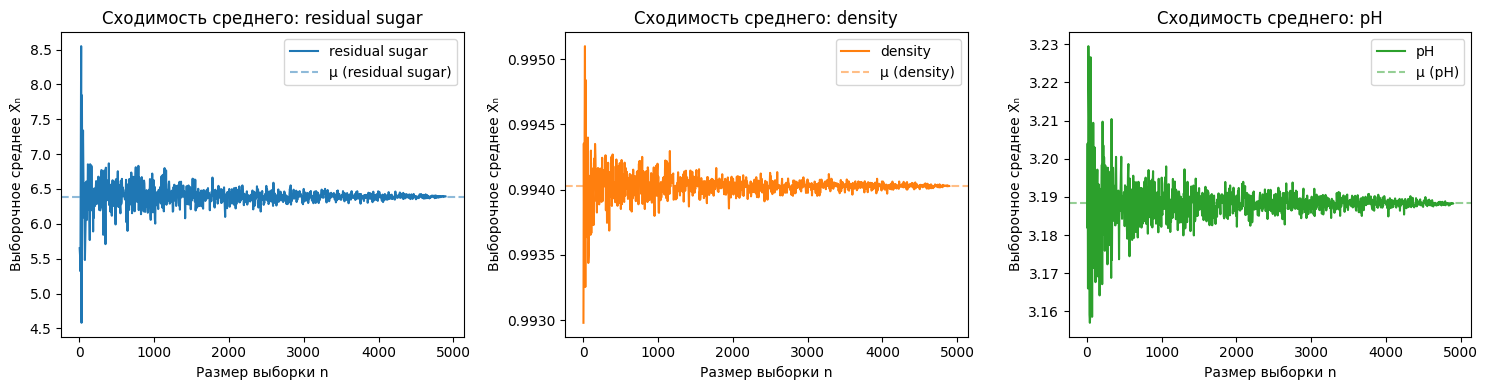

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

X = wine_quality['residual sugar']
Y = wine_quality['density']
Z = wine_quality['pH']

np.random.seed(42)
n_max = len(X)
ns = np.arange(5, n_max + 1, 5)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

data = [
    ("residual sugar", X, "C0"),
    ("density",        Y, "C1"),
    ("pH",             Z, "C2"),
]

for ax, (name, s, color) in zip(axes, data):
    means = [s.sample(n, random_state=i).mean() for i, n in enumerate(ns)]
    ax.plot(ns, means, color=color, label=name)
    ax.axhline(s.mean(), color=color, ls="--", alpha=0.5, label=f"μ ({name})")
    ax.set_xlabel("Размер выборки n")
    ax.set_ylabel("Выборочное среднее X̄ₙ")
    ax.set_title(f"Сходимость среднего: {name}")
    ax.legend()

plt.tight_layout()
plt.show()

**Замечания:**
* На графике наглядно видно, что при увеличении размера выборки n выборочное среднее $\bar{X_n}$ стабилизируется и стремится к истинному среднему значению μ (пунктирная линия), что визуально подтверждает ЗБЧ.
* Большая амплитуда колебаний графика residual_sugar связана с тем, что диспрсия данной величины как минимум на порядок больше, чем у остальных величин.

### **ЗБЧ**

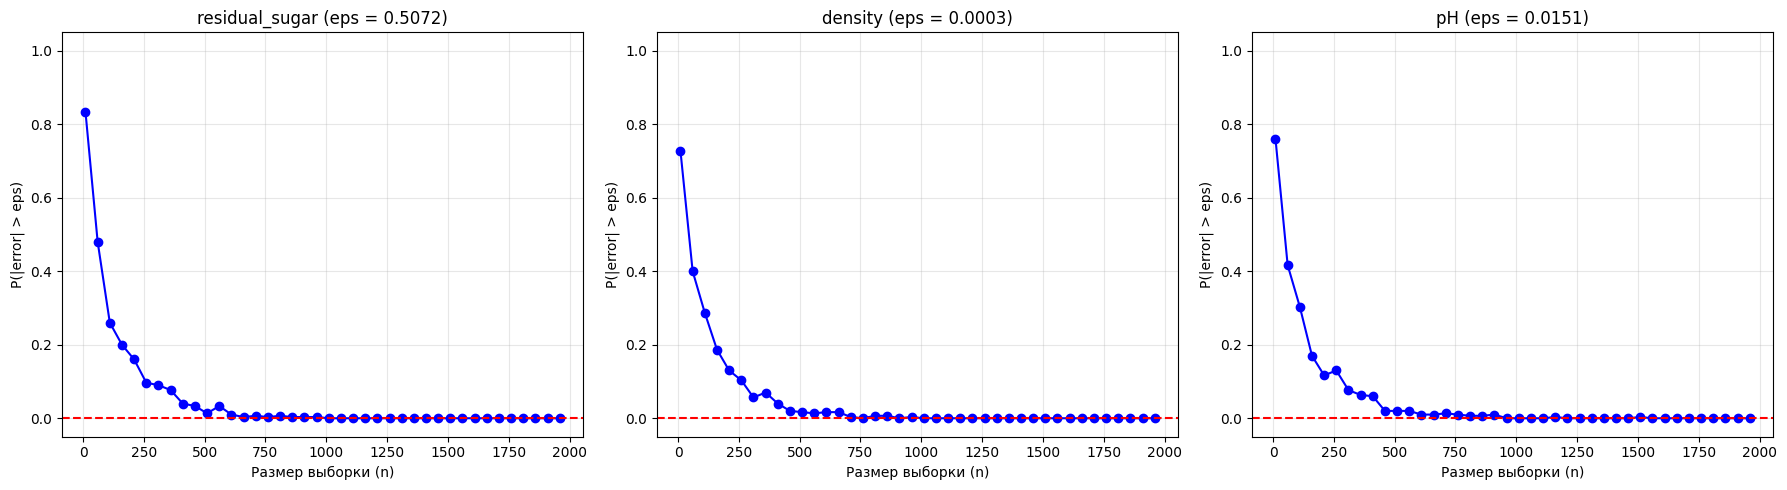

In [ ]:
datasets = [X, Y, Z]
names = ['residual_sugar', 'density', 'pH']
sample_sizes = np.arange(10, 2000, 50)
num_experiments = 300

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, data in enumerate(datasets):
    theta = np.mean(data)
    eps = 0.1 * data.std()

    probabilities = []

    for n in sample_sizes:
        count_exceed = 0
        for _ in range(num_experiments):
            sample = np.random.choice(data, size=n, replace=True)
            error = abs(np.mean(sample) - theta)

            if error > eps:
                count_exceed += 1

        probabilities.append(count_exceed / num_experiments)

    axes[i].plot(sample_sizes, probabilities, marker='o', linestyle='-', color='b')
    axes[i].axhline(0, color='red', linestyle='--')
    axes[i].set_title(f'{names[i]} (eps = {eps:.4f})')
    axes[i].set_xlabel('Размер выборки (n)')
    axes[i].set_ylabel('P(|error| > eps)')
    axes[i].grid(True, alpha=0.3)
    axes[i].set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.show()

**Замечания:**
* На графике наглядно видно, что вероятность события |$\bar{X_n}$ - μ| > eps приближается к 0 при увеличении размера n выборки. Это доказывает, что выборочное среднее $\bar{X_n}$ стремится к математическому ожиданию μ при n → ∞.
* Величины с большей дисперсией требуют большего размера выборки для достижения той же "точности".

## **Вывод**

* ЗБЧ выполняется, а значит состоятельность оценок подтверждена
* Подтверждение состоятельности означает, что при достаточно больших объемах данных мы можем доверять выборочному среднему как оценке генеральной совокупности, что является фундаментом для дальнейшего статистического анализа.

# **IV.  EDA и нормализация**


EDA (разведочный анализ) — здесь мы проводим первичное изучение таблицы до подбора сложных моделей. Мы изучаем есть ли пропуски, какие значения типичны, насколько велик разброс, есть ли асимметрия и насколько много потенциальных выбросов.

Зачем это нужно перед моделированием? Потому что выбранный метод зависит от свойств данных. Например, при сильной асимметрии среднее может плохо представлять центр, а нормальная модель может давать неудачное описание. Сначала изучаем данные, затем выбираем преобразование или модель.

Не будем удалять выбросы автоматически: по правилу IQR можно отметить необычные наблюдения, но это ещё не доказывает ошибку измерения.

In [ ]:
FEATURES = ['residual sugar', 'density', 'pH']
FEATURE_LABELS = {
    'residual sugar': 'Остаточный сахар, г/л',
    'density': 'Плотность, г/см³',
    'pH': 'pH, безразмерная шкала'
}

missing_columns = [c for c in FEATURES if c not in wine_quality.columns]
if missing_columns:
    raise KeyError(f'В таблице не найдены ожидаемые столбцы: {missing_columns}')

analysis_data = wine_quality[FEATURES].copy()
quality_check = pd.DataFrame({
    'тип данных': analysis_data.dtypes.astype(str),
    'пропуски': analysis_data.isna().sum(),
    'уникальные значения': analysis_data.nunique(),
})
display(quality_check)
print('Строк во всём датасете:', len(wine_quality))
print('Полных повторяющихся строк:', int(wine_quality.duplicated().sum()))
print('Пропусков в выбранных величинах:', int(analysis_data.isna().sum().sum()))

# Для следующих расчётов исключаем только строки с пропусками в выбранных переменных.
# Дубликаты оставляем: без описания происхождения данных нельзя считать их ошибками.
analysis_data = analysis_data.dropna().reset_index(drop=True)


,тип данных,пропуски,уникальные значения
residual sugar,float64,0,310
density,float64,0,890
pH,float64,0,103


Строк во всём датасете: 4898
Полных повторяющихся строк: 937
Пропусков в выбранных величинах: 0


### Описательные статистики, качество данных и выбросы

В ниже таблице базовые статистики: среднее, медиана, разброс, асимметрия, эксцесс. Отдельно показано число выбросов по правилу Тьюки.

 Границы по правилу Тьюки вычисляются так: нижняя граница равна $Q_1-1.5\,IQR$, верхняя — $Q_3+1.5\,IQR$, где $IQR=Q_3-Q_1$. Значения за этими границами на boxplot помечаются как потенциальные выбросы. Это сигнал для проверки, а не доказательство ошибки измерения: в химическом наборе крайнее значение может быть реальным образцом с необычным составом.

Относительный коэффициент вариации для pH не интерпретируем: pH сам является логарифмической шкалой, поэтому процентное отношение его стандартного отклонения к среднему не имеет такого же смысла, как для концентрации. В таблице для pH это поле не рассчитывается.

,n,среднее,медиана,ст. отклонение s,дисперсия s²,Q1,Q3,IQR,минимум,максимум,асимметрия,эксцесс (Fisher),"коэфф. вариации, %",потенциальные выбросы по IQR
"Остаточный сахар, г/л",4898.0,6.39141,5.20000,5.07206,25.72577,1.70000,9.9000,8.20000,0.60000,65.80000,1.07709,3.46982,79.35736,7.0
"Плотность, г/см³",4898.0,0.99403,0.99374,0.00299,0.00001,0.99172,0.9961,0.00438,0.98711,1.03898,0.97777,9.79381,0.30089,5.0
"pH, безразмерная шкала",4898.0,3.18827,3.18000,0.15100,0.02280,3.09000,3.2800,0.19000,2.72000,3.82000,0.45778,0.53077,4.73613,75.0


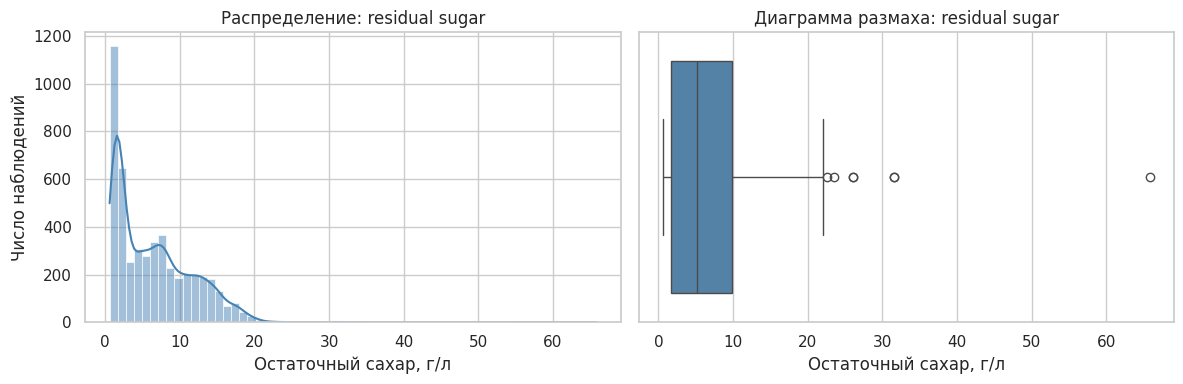

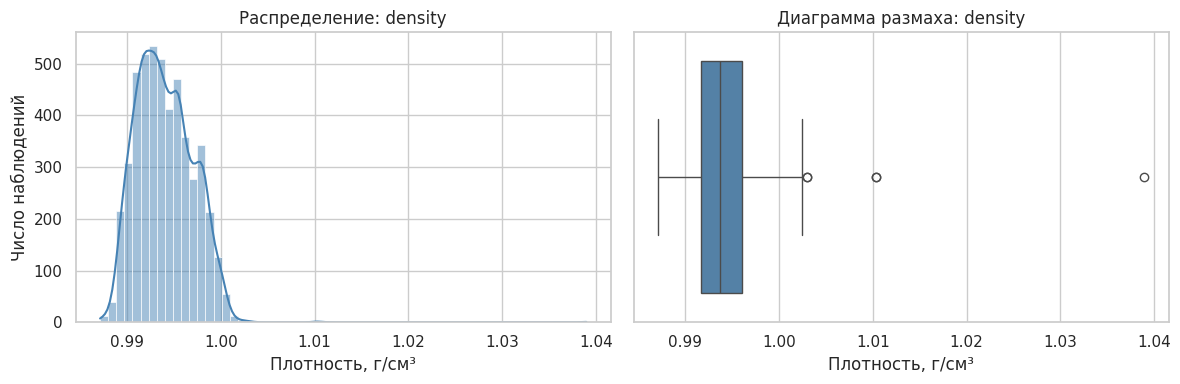

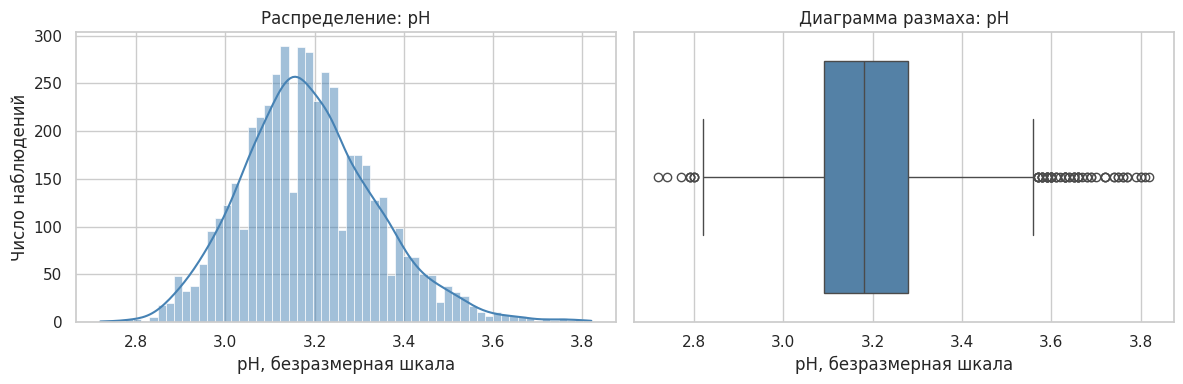

In [ ]:
def describe_one(series):
    x = series.dropna().to_numpy(dtype=float)
    q1, q3 = np.quantile(x, [0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mean = x.mean()
    sd_sample = x.std(ddof=1)
    return {
        'n': len(x),
        'среднее': mean,
        'медиана': np.median(x),
        'ст. отклонение s': sd_sample,
        'дисперсия s²': x.var(ddof=1),
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'минимум': x.min(),
        'максимум': x.max(),
        'асимметрия': stats.skew(x, bias=False),
        'эксцесс (Fisher)': stats.kurtosis(x, fisher=True, bias=False),
        'коэфф. вариации, %': 100 * sd_sample / mean if mean != 0 else np.nan,
        'потенциальные выбросы по IQR': int(((x < lower) | (x > upper)).sum()),
    }

eda_summary = pd.DataFrame({col: describe_one(analysis_data[col]) for col in FEATURES}).T
eda_summary.index = [FEATURE_LABELS[c] for c in eda_summary.index]
display(eda_summary.round(5))

sns.set_theme(style='whitegrid', context='notebook')
for col in FEATURES:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    x = analysis_data[col]
    sns.histplot(x, color='steelblue', bins=60, kde=True, ax=axes[0])
    axes[0].set_title(f'Распределение: {col}')
    axes[0].set_xlabel(FEATURE_LABELS[col])
    axes[0].set_ylabel('Число наблюдений')
    sns.boxplot(color='steelblue', x=x, ax=axes[1], orient='h')
    axes[1].set_title(f'Диаграмма размаха: {col}')
    axes[1].set_xlabel(FEATURE_LABELS[col])
    plt.tight_layout()
    plt.show()


### Что показывают описательные статистики
Три величины ведут себя по-разному, и это видно по таблице.

**residual sugar.** Среднее 6.39 заметно больше медианы 5.2 (разница 1.19, или 23% от медианы) — это признак правой асимметрии, которую подтверждает коэффициент асимметрии 1.08. Верхний квартиль $Q_3 = 9.9$, а максимум 65.8 — в 6.6 раза дальше от $Q_3$, чем сам $Q_3$ от медианы. При этом 95% значений не превышают 15.7, то есть несколько очень сладких вин сильно тянут среднее вверх. По правилу Тьюки ($Q_1 - 1.5 \cdot IQR = 1.7 - 12.3 = -10.6$; $Q_3 + 1.5 \cdot IQR = 9.9 + 12.3 = 22.2$) за верхнюю границу выходят всего 7 наблюдений (0.14%), но именно они дают такой длинный хвост. Коэффициент вариации 79% — очень высокий разброс относительно среднего; для остаточного сахара это ожидаемо, потому что в датасете смешаны сухие и сладкие вина.

**density.** Среднее 0.99403 и медиана 0.99374 практически совпадают (разница 0.0003, или 0.03%) — по центральной тенденции распределение симметрично. Но эксцесс 9.79 очень высокий: это означает тяжёлые хвосты. Действительно, $Q_3 = 0.9961$, а максимум 1.03898 — на 4.3% выше $Q_3$, что для плотности, меняющейся в пределах 0.987–1.039, очень много. Правило Тьюки даёт всего 5 выбросов (0.1%), но они сильно влияют на эксцесс. Стандартное отклонение 0.003 показывает, что основная масса данных очень кучная — это согласуется с тем, что плотность вина близка к плотности воды.

**pH.** Среднее 3.188 и медиана 3.18 почти равны — распределение близко к симметричному. Асимметрия 0.46 и эксцесс 0.53 умеренные. При этом по IQR формально 75 выбросов (1.5%) — это много. Причина в том, что pH в датасете дискретный: всего 103 уникальных значения, $IQR = 0.19$ узкий, поэтому правило Тьюки ($Q_1 - 1.5 \cdot IQR = 3.09 - 0.285 = 2.805$; $Q_3 + 1.5 \cdot IQR = 3.28 + 0.285 = 3.565$) захватывает значения, которые для непрерывной величины были бы нормальными. Так что эти 75 точек — выбросы только формально. На самом деле это обычные значения pH, просто правило Тьюки сработало слишком строго, потому что у pH узкий IQR.

### Нормализация: что реально изменилось

Z-преобразование и нормализация не меняют форму распределения — асимметрия до и после z одинаковая (1.077 для residual sugar, 0.978 для density, 0.458 для pH). Это ожидаемо: линейные преобразования не влияют на форму. Зато они приводят величины к общей шкале: после z все три имеют среднее $\approx 0$ и СКО $\approx 1$, после нормализации — диапазон $[0, 1]$. Для совместного анализа это удобно, но для интерпретации химических величин нужно возвращаться к исходным единицам.

Логарифмирование residual sugar уменьшило модуль асимметрии с 1.077 до 0.161 (в 6.7 раза) и эксцесс с 3.47 до −1.35. Распределение стало ближе к симметричному, хотя появилась небольшая левая асимметрия (−0.16). Это значит, что $\ln(\text{residual sugar})$ — более удачная шкала для моделирования, чем исходная, но и она не делает величину нормальной: эксцесс −1.35 говорит о распределении без выраженного пика.

Для density и pH логарифмирование не требуется: density сконцентрирована около 1, а pH сам по себе логарифмическая характеристика концентрации ионов водорода.

,среднее до,СКО до (ddof=0),среднее после z,СКО после z,min после Min–Max,max после Min–Max,асимметрия до,асимметрия после z
величина,,,,,,,,
residual sugar,6.39141,5.07154,-0.0,1.0,0.0,1.0,1.07709,1.07709
density,0.99403,0.00299,0.0,1.0,0.0,1.0,0.97777,0.97777
pH,3.18827,0.15099,-0.0,1.0,0.0,1.0,0.45778,0.45778


,исходный residual sugar,ln(residual sugar)
показатель,,
среднее,6.39141,1.48093
медиана,5.20000,1.64866
СКО,5.07206,0.92175
асимметрия,1.07709,-0.16116
эксцесс,3.46982,-1.35235


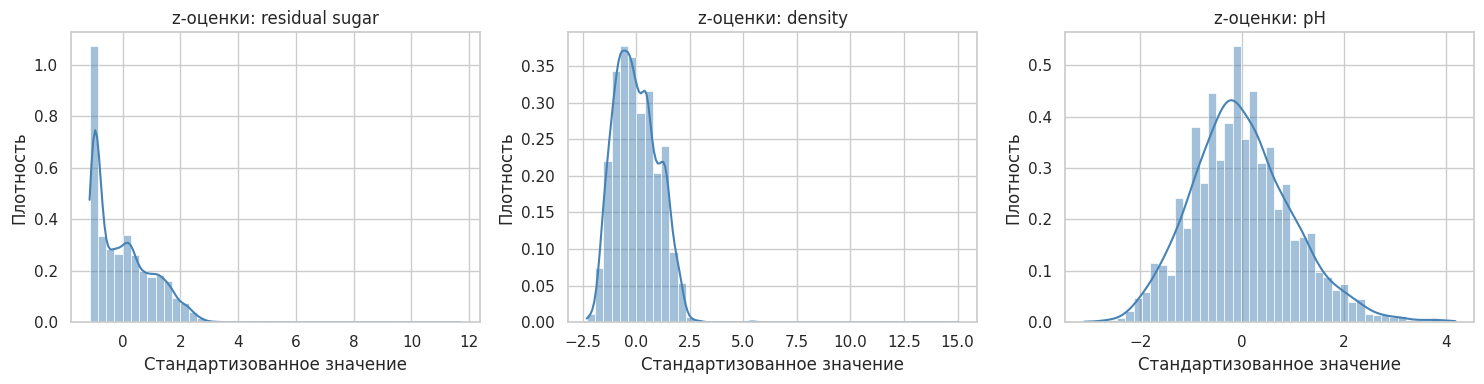

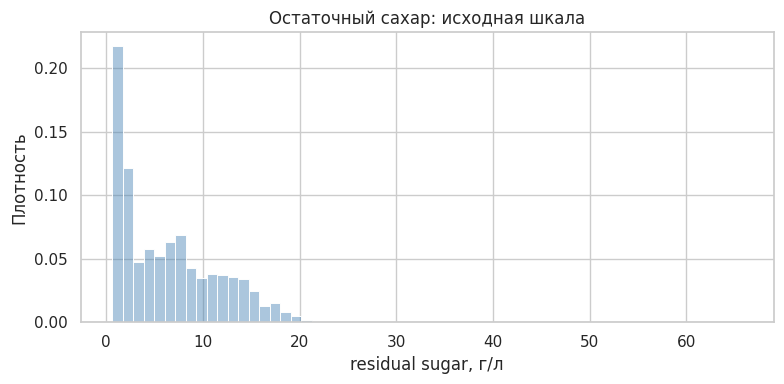

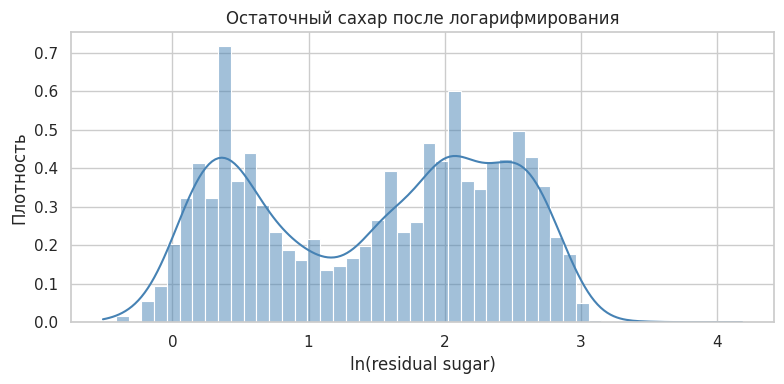

In [ ]:
z_scaled = pd.DataFrame(index=analysis_data.index)
minmax_scaled = pd.DataFrame(index=analysis_data.index)
normalization_rows = []

for col in FEATURES:
    x = analysis_data[col].astype(float)
    z_scaled[col] = (x - x.mean()) / x.std(ddof=0)
    span = x.max() - x.min()
    minmax_scaled[col] = (x - x.min()) / span if span != 0 else 0.0
    normalization_rows.append({
        'величина': col,
        'среднее до': x.mean(),
        'СКО до (ddof=0)': x.std(ddof=0),
        'среднее после z': z_scaled[col].mean(),
        'СКО после z': z_scaled[col].std(ddof=0),
        'min после Min–Max': minmax_scaled[col].min(),
        'max после Min–Max': minmax_scaled[col].max(),
        'асимметрия до': stats.skew(x, bias=False),
        'асимметрия после z': stats.skew(z_scaled[col], bias=False),
    })

normalization_table = pd.DataFrame(normalization_rows).set_index('величина')
display(normalization_table.round(5))

# Логарифмируем только остаточный сахар и сравниваем его форму до/после.
log_residual_sugar = np.log(analysis_data['residual sugar'])
log_comparison = pd.DataFrame({
    'показатель': ['среднее', 'медиана', 'СКО', 'асимметрия', 'эксцесс'],
    'исходный residual sugar': [
        analysis_data['residual sugar'].mean(),
        analysis_data['residual sugar'].median(),
        analysis_data['residual sugar'].std(ddof=1),
        stats.skew(analysis_data['residual sugar'], bias=False),
        stats.kurtosis(analysis_data['residual sugar'], fisher=True, bias=False),
    ],
    'ln(residual sugar)': [
        log_residual_sugar.mean(),
        log_residual_sugar.median(),
        log_residual_sugar.std(ddof=1),
        stats.skew(log_residual_sugar, bias=False),
        stats.kurtosis(log_residual_sugar, fisher=True, bias=False),
    ]
}).set_index('показатель')
display(log_comparison.round(5))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, FEATURES):
    sns.histplot(z_scaled[col], color='steelblue', bins=45, stat='density', kde=True, ax=ax)
    ax.set_title(f'z-оценки: {col}')
    ax.set_xlabel('Стандартизованное значение')
    ax.set_ylabel('Плотность')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(analysis_data['residual sugar'], color='steelblue', bins=60, stat='density', ax=ax, label='исходная шкала', alpha=0.45)
ax.set_xlabel('residual sugar, г/л')
ax.set_ylabel('Плотность')
ax.set_title('Остаточный сахар: исходная шкала')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(log_residual_sugar, color='steelblue', bins=50, stat='density', kde=True, ax=ax)
ax.set_xlabel('ln(residual sugar)')
ax.set_ylabel('Плотность')
ax.set_title('Остаточный сахар после логарифмирования')
plt.tight_layout()
plt.show()


In [ ]:
# Оцениваем, изменилось ли направление и выраженность асимметрии после ln-преобразования.
skew_before = stats.skew(analysis_data['residual sugar'], bias=False)
skew_after = stats.skew(log_residual_sugar, bias=False)
print(f'Асимметрия до логарифмирования: {skew_before:.4f}')
print(f'Асимметрия после логарифмирования: {skew_after:.4f}')
if abs(skew_after) < abs(skew_before):
    print('В этой таблице логарифмирование уменьшило модуль асимметрии.')
else:
    print('В этой таблице логарифмирование не уменьшило модуль асимметрии.')
print('Это сравнение описывает форму распределения, но само по себе не доказывает нормальность.')

Асимметрия до логарифмирования: 1.0771
Асимметрия после логарифмирования: -0.1612
В этой таблице логарифмирование уменьшило модуль асимметрии.
Это сравнение описывает форму распределения, но само по себе не доказывает нормальность.


### Вывод по EDA и нормализации

1. Пропусков нет, после подготовки осталось 4898 строк. 937 полных дубликатов мы не удаляли — без идентификатора бутылки нельзя доказать, что это технические повторы, а не разные образцы с совпавшими округлёнными измерениями.
2. Форма распределений разная: **residual sugar** имеет правую асимметрию (1.08) и длинный хвост (max 65.8 против $Q_3 = 9.9$); **density** симметрична по центру, но с высоким эксцессом 9.79 из-за нескольких экстремальных значений; **pH** близок к нормальному (асимметрия 0.46, эксцесс 0.53), а 75 «выбросов» — следствие дискретности шкалы.
3. Логарифмирование residual sugar уменьшило асимметрию с 1.08 до 0.16, но не сделало распределение нормальным (эксцесс стал −1.35). Это преобразование — разумный шаг для моделирования, но не универсальное решение.
4. Стандартизация и нормализация привели величины к общему масштабу, но не изменили форму распределений.

# **V. Выборка и сравнение с эмпирической генеральной совокупностью**



Теперь мы  моделируем ситуацию, когда вся таблица нам не доступна и мы видим только часть наблюдений. Для эксперимента считаем эмпирической генеральной совокупностью все строки исходного набора без пропусков в трёх выбранных столбцах. Средние и медианы по полной таблице будут опорными значениями, с которыми сравним выборочные оценки.

Для ориентировочного расчёта объёма выборки зададим доверительную вероятность 95% и желаемую полуширину интервала для среднего не более $0.1\sigma$, то есть 10% стандартного отклонения. При нормальном приближении без поправки на конечный размер получается

$$
n_0=\left(\frac{1.96}{0.1}\right)^2\approx384.
$$

Здесь 10% относятся к стандартному отклонению. Для отбора без возвращения используем поправку на конечную совокупность:

$$
n=\frac{Nn_0}{N+n_0-1}.
$$

Для сопоставимого сравнения возьмём 400 строк. Построим выборку двумя способами: без возвращения (строка выбирается не более одного раза) и с возвращением (одна строка может встретиться повторно). Фиксируем `seed`, чтобы результат можно было воспроизвести при повторном запуске.

In [ ]:
# Повторно создаём набор анализа без пропусков и задаём параметры выборочного исследования.
population = wine_quality[FEATURES].dropna().reset_index(drop=True)
N = len(population)
alpha = 0.05
z_critical = stats.norm.ppf(1 - alpha / 2)
relative_half_width = 0.10
n0 = (z_critical / relative_half_width) ** 2
n_without_required = int(np.ceil(N * n0 / (N + n0 - 1)))
n_with_required = int(np.ceil(n0))
SAMPLE_N = min(N, max(400, n_without_required, n_with_required))

print(f'Размер эмпирической совокупности N = {N}')
print(f'Расчёт без возвращения с поправкой на конечную совокупность: n ≈ {n_without_required}')
print(f'Ориентир без поправки на конечную совокупность: n ≈ {n_with_required}')
print(f'Фактический размер обеих сравниваемых выборок: n = {SAMPLE_N}')

rng = np.random.default_rng(20261017)
indices_without = rng.choice(N, size=SAMPLE_N, replace=False)
indices_with = rng.choice(N, size=SAMPLE_N, replace=True)

sample_without = population.iloc[indices_without].reset_index(drop=True)
sample_with = population.iloc[indices_with].reset_index(drop=True)

sample_comparison_rows = []
for col in FEATURES:
    x_pop = population[col].to_numpy(dtype=float)
    pop_mean = x_pop.mean()
    pop_median = np.median(x_pop)
    pop_sd_ddof0 = x_pop.std(ddof=0)
    for method, sample in [('Без возвращения', sample_without), ('С возвращением', sample_with)]:
        x_s = sample[col].to_numpy(dtype=float)
        sample_mean = x_s.mean()
        sample_median = np.median(x_s)
        sample_sd = x_s.std(ddof=1)
        sample_comparison_rows.append({
            'величина': col,
            'способ': method,
            'среднее совокупности': pop_mean,
            'среднее выборки': sample_mean,
            'ошибка среднего': sample_mean - pop_mean,
            'относительная ошибка среднего, %': 100 * (sample_mean - pop_mean) / pop_mean if pop_mean != 0 else np.nan,
            'медиана совокупности': pop_median,
            'медиана выборки': sample_median,
            'СКО совокупности (ddof=0)': pop_sd_ddof0,
            'СКО выборки (ddof=1)': sample_sd,
        })

sample_comparison = pd.DataFrame(sample_comparison_rows)
display(sample_comparison.round(5))

print('Число повторяющихся индексов в выборке с возвращением:', SAMPLE_N - len(np.unique(indices_with)))
print('Число повторяющихся индексов в выборке без возвращения:', SAMPLE_N - len(np.unique(indices_without)))


Размер эмпирической совокупности N = 4898
Расчёт без возвращения с поправкой на конечную совокупность: n ≈ 357
Ориентир без поправки на конечную совокупность: n ≈ 385
Фактический размер обеих сравниваемых выборок: n = 400


,величина,способ,среднее совокупности,среднее выборки,ошибка среднего,"относительная ошибка среднего, %",медиана совокупности,медиана выборки,СКО совокупности (ddof=0),СКО выборки (ddof=1)
0,residual sugar,Без возвращения,6.39141,6.10100,-0.29041,-4.54383,5.20000,4.5250,5.07154,5.10631
1,residual sugar,С возвращением,6.39141,6.62125,0.22984,3.59600,5.20000,5.9250,5.07154,5.70522
2,density,Без возвращения,0.99403,0.99380,-0.00023,-0.02303,0.99374,0.9934,0.00299,0.00301
3,density,С возвращением,0.99403,0.99431,0.00028,0.02845,0.99374,0.9939,0.00299,0.00368
4,pH,Без возвращения,3.18827,3.17902,-0.00924,-0.28986,3.18000,3.1800,0.15099,0.14406
5,pH,С возвращением,3.18827,3.18525,-0.00302,-0.09462,3.18000,3.1800,0.15099,0.14617


Число повторяющихся индексов в выборке с возвращением: 4
Число повторяющихся индексов в выборке без возвращения: 0


### Что показывают выборки

**residual sugar** — самая р величина. Без возвращения среднее 6.101 (ошибка −0.290, или −4.54% от среднего совокупности), с возвращением 6.621 (ошибка +0.230, или +3.60%). Медианы выборок 4.525 и 5.925 против 5.2 в совокупности. Такой разброс объясняется высоким коэффициентом вариации = 79\%: при выборке 400 из 4898 стандартная ошибка среднего $\approx 5.07/\sqrt{400} \approx 0.25$, что и даёт наблюдаемые отклонения порядка 0.2–0.3.

**density** — наоборот, очень стабильна. Ошибки −0.023% и +0.028% — практически нулевые. Это прямое следствие малого коэффициента вариации = 0.3\%: стандартная ошибка $\approx 0.003/\sqrt{400} \approx 0.00015$, что на порядок меньше самого СКО.

**pH** — промежуточный случай. Ошибки −0.29% и −0.095%, стандартная ошибка $\approx 0.151/\sqrt{400} \approx 0.0076$. Обе выборки дали среднее чуть ниже истинного, но в пределах ожидаемого.



### Повторный эксперимент: точность и доверительные интервалы

Один запуск показывает лишь одну реализацию случайного отбора. Поэтому дальше повторяем отбор 500 раз для каждого признака и каждого способа. Для каждой повторной выборки сохраняем среднее, строим 95%-й $t$-интервал и проверяем, содержит ли он опорное среднее всей эмпирической совокупности.

В итоговой таблице важны три числа. Смещение — средняя знаковая ошибка; около нуля означает, что метод не завышает и не занижает оценку систематически. RMSE — корень из средней квадратичной ошибки: учитывает одновременно случайный разброс и смещение, причём крупные ошибки влияют сильнее. Покрытие — доля повторов, в которых интервал включил опорное среднее. При 500 повторах покрытие не обязано равняться ровно 95%; даже если процедура идеальна, результат колеблется из-за конечного числа повторов.

,величина,способ,среднее оценок,смещение оценки,RMSE,СКО выборочных средних,"покрытие 95%-х интервалов, %"
0,residual sugar,Без возвращения,6.37954,-0.01188,0.25770,0.25769,93.0
1,residual sugar,С возвращением,6.38686,-0.00455,0.26539,0.26561,93.4
2,density,Без возвращения,0.99403,-0.00000,0.00015,0.00015,93.4
3,density,С возвращением,0.99403,0.00000,0.00015,0.00015,95.0
4,pH,Без возвращения,3.18871,0.00044,0.00744,0.00743,94.4
5,pH,С возвращением,3.18842,0.00016,0.00730,0.00730,94.0


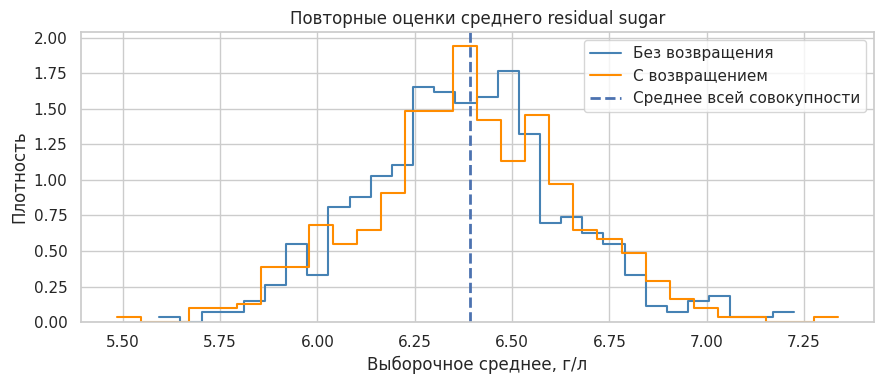

In [ ]:
def repeated_sampling_summary(pop_df, n, repetitions=500, seed=20261018):
    """Сравнить оценку среднего и покрытие 95%-го интервала при двух схемах отбора."""
    local_rng = np.random.default_rng(seed)
    N_local = len(pop_df)
    t_critical = stats.t.ppf(0.975, df=n - 1)
    results = []
    sample_mean_draws = {col: {'Без возвращения': [], 'С возвращением': []} for col in FEATURES}

    for col in FEATURES:
        values = pop_df[col].to_numpy(dtype=float)
        reference_mean = values.mean()
        for replace, method in [(False, 'Без возвращения'), (True, 'С возвращением')]:
            estimates = np.empty(repetitions)
            covered = np.empty(repetitions, dtype=bool)
            fpc = np.sqrt(1 - n / N_local) if not replace else 1.0
            for b in range(repetitions):
                idx = local_rng.choice(N_local, size=n, replace=replace)
                draw = values[idx]
                estimate = draw.mean()
                s = draw.std(ddof=1)
                se = (s / np.sqrt(n)) * fpc
                lo, hi = estimate - t_critical * se, estimate + t_critical * se
                estimates[b] = estimate
                covered[b] = (lo <= reference_mean <= hi)
            sample_mean_draws[col][method] = estimates.tolist()
            errors = estimates - reference_mean
            results.append({
                'величина': col,
                'способ': method,
                'среднее оценок': estimates.mean(),
                'смещение оценки': errors.mean(),
                'RMSE': np.sqrt(np.mean(errors ** 2)),
                'СКО выборочных средних': estimates.std(ddof=1),
                'покрытие 95%-х интервалов, %': 100 * covered.mean(),
            })
    return pd.DataFrame(results), sample_mean_draws

repeated_results, sample_mean_draws = repeated_sampling_summary(
    population, SAMPLE_N, repetitions=500, seed=20261018
)
display(repeated_results.round(5))

# Распределение оценок среднего остаточного сахара по повторным выборкам.
col = 'residual sugar'
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(sample_mean_draws[col]['Без возвращения'], color='steelblue', stat='density', bins=30,
             element='step', fill=False, ax=ax, label='Без возвращения')
sns.histplot(sample_mean_draws[col]['С возвращением'], color='darkorange', stat='density', bins=30,
             element='step', fill=False, ax=ax, label='С возвращением')
ax.axvline(population[col].mean(), linestyle='--', linewidth=2, label='Среднее всей совокупности')
ax.set_title('Повторные оценки среднего residual sugar')
ax.set_xlabel('Выборочное среднее, г/л')
ax.set_ylabel('Плотность')
ax.legend()
plt.tight_layout()
plt.show()


### Вывод по выборке и повторным отборам

По 500 повторов видно, что обе схемы отбора дают практически несмещённые оценки: смещение для residual sugar −0.012 (без возвращения) и −0.005 (с возвращением), для density и pH — на уровне $10^{-4}$–$10^{-5}$. RMSE для residual sugar 0.258 и 0.265 — это средний масштаб ошибки, который согласуется с теоретической стандартной ошибкой 0.25. Для density RMSE 0.00015, для pH 0.0074 — тоже соответствуют $\sigma/\sqrt{n}$.

Покрытие 95%-х интервалов: 93.0–95.0%. Для residual sugar без возвращения 93.0% — чуть ниже номинала, но при 500 повторах стандартная ошибка доли $\approx \sqrt{0.95 \cdot 0.05 / 500} \approx 0.97\%$, так что 93.0% находится на нижней границе допустимого ($95\% \pm 2$ стандартные ошибки $\approx [93.1\%; 96.9\%]$). Для density с возвращением покрытие ровно 95.0% — идеальное совпадение. В целом интервалы откалиброваны корректно.

Разница между схемами отбора по RMSE небольшая: для residual sugar 0.258 против 0.265. Без возвращения оценка чуть точнее, что ожидаемо: поправка на конечную совокупность $\sqrt{1 - n/N} = \sqrt{1 - 400/4898} \approx 0.958$ уменьшает стандартную ошибку примерно на 4%. Для density и pH разница ещё меньше.

# **VI. Математическое описание распределений**



 Сравним для каждой величины нормальное, логнормальное и гамма-распределение. Это проверка того, какая из моделей лучше согласуется с данными по выбранному критерию.

### Нормальное распределение

$$
X\sim\mathcal{N}(\mu,\sigma^2),\qquad
f(x)=\frac{1}{\sigma\sqrt{2\pi}}\exp\!\left[-\frac{(x-\mu)^2}{2\sigma^2}\right],\quad x\in\mathbb{R}.
$$

Нормальное распределение симметрично относительно $\mu$; его среднее, медиана и мода совпадают. Недостаток для химических величин, таких как остаточный сахар: нормальная модель допускает отрицательные значения.

### Логнормальное распределение

Если $\ln X\sim\mathcal{N}(\mu,\sigma^2)$, то $X$ имеет логнормальное распределение с плотностью

$$
f(x)=\frac{1}{x\sigma\sqrt{2\pi}}\exp\!\left[-\frac{(\ln x-\mu)^2}{2\sigma^2}\right],\quad x>0.
$$

Оно допускает только положительные значения и может иметь длинный правый хвост. Его среднее равно $\exp(\mu+\sigma^2/2)$, а дисперсия — $(\exp(\sigma^2)-1)\exp(2\mu+\sigma^2)$. Поэтому такая модель лучший вариант для положительной величины с выраженной правой асимметрией, например остаточного сахара.

### Гамма-распределение

Для параметров формы $k>0$ и масштаба $\theta>0$ плотность гамма-распределения равна

$$
f(x)=\frac{x^{k-1}e^{-x/\theta}}{\Gamma(k)\theta^k},\quad x>0,
\qquad \mathbb{E}[X]=k\theta,\quad \operatorname{Var}(X)=k\theta^2.
$$

Это ещё одна модель на положительной полуоси; изменение параметра формы позволяет описывать разную степень асимметрии.

### Как сравниваем модели

Используем информационный критерий Байеса:

$$
BIC=k\ln(n)-2\ln\hat{L},
$$

где $k$ — число оцениваемых параметров, $n$ — число наблюдений, а $\hat{L}$ — максимальное правдоподобие модели. Модель с меньшим BIC предпочтительнее среди сравниваемых моделей, критерий учитывает и согласование с данными, и число параметров.



,величина,модель,оценённые параметры,log-likelihood,AIC,BIC
0,density,"Логнормальное, loc=0","(0.003004, 0.0, 0.994023)",21525.578,-43047.157,-43034.164
1,density,"Гамма, loc=0","(110689.918775, 0.0, 9e-06)",21523.277,-43042.553,-43029.560
2,density,Нормальное,"(0.994027, 0.002991)",21518.590,-43033.180,-43020.187
3,pH,"Логнормальное, loc=0","(0.046992, 0.0, 3.184732)",2353.347,-4702.693,-4689.700
4,pH,"Гамма, loc=0","(450.879387, 0.0, 0.007071)",2340.870,-4677.741,-4664.748
5,pH,Нормальное,"(3.188267, 0.150985)",2310.068,-4616.137,-4603.144
6,residual sugar,"Гамма, loc=0","(1.481406, 0.0, 4.314424)",-13777.793,27559.586,27572.579
7,residual sugar,"Логнормальное, loc=0","(0.921651, 0.0, 4.397022)",-13803.925,27611.850,27624.843
8,residual sugar,Нормальное,"(6.391415, 5.07154)",-14902.572,29809.144,29822.137


residual sugar: минимальный BIC у модели «Гамма, loc=0»; параметры = (1.481406, 0.0, 4.314424)
density: минимальный BIC у модели «Логнормальное, loc=0»; параметры = (0.003004, 0.0, 0.994023)
pH: минимальный BIC у модели «Логнормальное, loc=0»; параметры = (0.046992, 0.0, 3.184732)


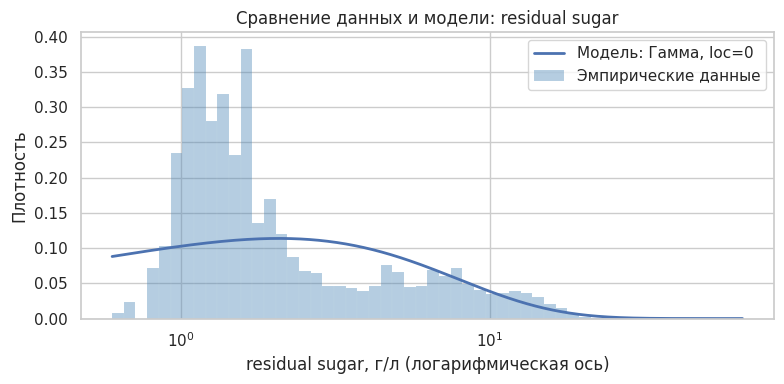

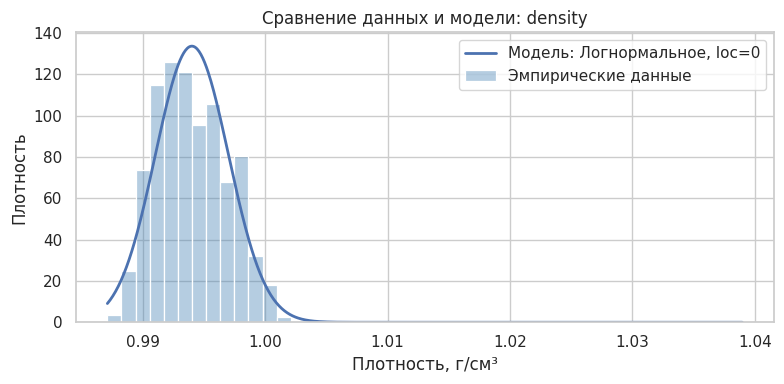

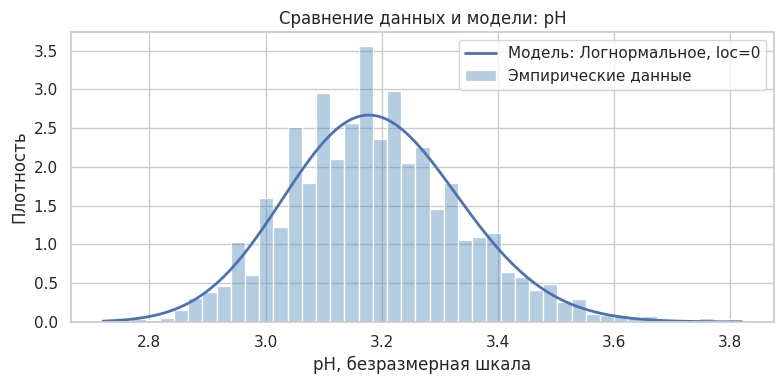

In [ ]:
DISTRIBUTION_CANDIDATES = {
    'Нормальное': (stats.norm, False, 2),
    'Логнормальное, loc=0': (stats.lognorm, True, 2),
    'Гамма, loc=0': (stats.gamma, True, 2),
}
fit_rows = []
fit_details = {}

for col in FEATURES:
    x = population[col].to_numpy(dtype=float)
    fit_details[col] = {}
    for model_name, (distribution, fix_location_zero, k_parameters) in DISTRIBUTION_CANDIDATES.items():
        if fix_location_zero:
            params = distribution.fit(x, floc=0)
        else:
            params = distribution.fit(x)
        log_likelihood = float(np.sum(distribution.logpdf(x, *params)))
        k = k_parameters  # loc=0 фиксирован, поэтому не считается оценённым параметром.
        aic = 2 * k - 2 * log_likelihood
        bic = k * np.log(len(x)) - 2 * log_likelihood
        fit_details[col][model_name] = {
            'distribution': distribution,
            'params': params,
            'AIC': aic,
            'BIC': bic,
            'log_likelihood': log_likelihood,
        }
        fit_rows.append({
            'величина': col,
            'модель': model_name,
            'оценённые параметры': str(tuple(round(float(p), 6) for p in params)),
            'log-likelihood': log_likelihood,
            'AIC': aic,
            'BIC': bic,
        })

fit_table = pd.DataFrame(fit_rows).sort_values(['величина', 'BIC']).reset_index(drop=True)
display(fit_table.round(3))

best_models = {}
for col in FEATURES:
    best_name = min(fit_details[col], key=lambda name: fit_details[col][name]['BIC'])
    best_models[col] = best_name
    best = fit_details[col][best_name]
    print(f'{col}: минимальный BIC у модели «{best_name}»; параметры = {tuple(round(float(p), 6) for p in best["params"])}')

# Эмпирическая гистограмма и плотность модели с наименьшим BIC для каждой величины.
for col in FEATURES:
    x = population[col].to_numpy(dtype=float)
    model_name = best_models[col]
    model = fit_details[col][model_name]
    distribution = model['distribution']
    params = model['params']
    fig, ax = plt.subplots(figsize=(8, 4))
    if col == 'residual sugar':
        bins = np.geomspace(x.min(), x.max(), 55)
        grid = np.geomspace(x.min(), x.max(), 700)
    else:
        bins = 45
        grid = np.linspace(x.min(), x.max(), 700)
    sns.histplot(x, color='steelblue', bins=bins, stat='density', ax=ax, alpha=0.4, label='Эмпирические данные')
    ax.plot(grid, distribution.pdf(grid, *params), linewidth=2,
            label=f'Модель: {model_name}')
    if col == 'residual sugar':
        ax.set_xscale('log')
        ax.set_xlabel('residual sugar, г/л (логарифмическая ось)')
    else:
        ax.set_xlabel(FEATURE_LABELS[col])
    ax.set_ylabel('Плотность')
    ax.set_title(f'Сравнение данных и модели: {col}')
    ax.legend()
    plt.tight_layout()
    plt.show()


### Что показал подбор распределений

**residual sugar.** Минимальный BIC у гамма-распределения 27572.6, у логнормального 27624.8, у нормального 29822.1. Разница между гамма и логнормальным 52.2. Нормальное проигрывает на 2249, то есть категорически не подходит. Параметры гамма $k = 1.481$, $\theta = 4.314$ дают $k\theta = 6.391$ — точное совпадение с выборочным средним, а $k\theta^2 = 27.6$ при выборочной дисперсии 25.7. Логнормальное с $\sigma = 0.922$ предсказывает $E[X] = \exp(1.481 + 0.922^2/2) \approx 6.72$, что выше наблюдаемого 6.39. Именно это расхождение и объясняет, почему гамма выигрывает: она лучше воспроизводит и среднее, и дисперсию.

**density.** Логарифмически нормальное BIC −43034.2 и гамма −43029.6 практически неразличимы: $\Delta BIC = 4.6$. Нормальное отстаёт на 14. Параметры логнормального $\sigma = 0.003004$, scale $= 0.994023$, то есть $\ln(\text{density}) \sim \mathcal{N}(-0.006, 0.003^2)$. Поскольку $\sigma$ очень мало, логнормальное распределение в этом диапазоне почти неотличимо от нормального — что и объясняет близость BIC.

**pH.** Логарифмически нормальное −4689.7 лучше гамма −4664.7 с $\Delta BIC = 25$ и нормального −4603.1 с $\Delta BIC = 86.6$. Параметры $\sigma = 0.047$, scale $= 3.1847$. Как и для density, малое $\sigma$ делает логнормальное распределение близким к нормальному.

**Общий вывод.** Для положительных правоасимметричных величин (residual sugar) гамма и логнормальное распределения подходят лучше нормального; для величин, сконцентрированных около 1 (density) или имеющих малый разброс (pH), логнормальное и нормальное почти эквивалентны. Нормальное распределение проигрывает везде — это согласуется с тем, что все три величины имеют положительную асимметрию.


# **VII. Проверка статистической гипотезы**



После EDA у остаточного сахара видна правая асимметрия, поэтому проверим гипотезу о нормальности.

- $H_0$: значения `residual sugar` согласуются с нормальным распределением с неизвестными параметрами $\mu$ и $\sigma^2$.
- $H_1$: распределение `residual sugar` отличается от нормального.
- Уровень значимости: $\alpha=0.05$.

Используем критерий Д’Агостино — Пирсона (`scipy.stats.normaltest`), который объединяет информацию об асимметрии и эксцессе. Если `p-value < 0.05`(вероятность увидеть данные с нормальным распределением), отвергаем $H_0$. Если `p-value` больше или равен 0,05, у нас нет достаточных оснований отвергнуть $H_0$, но в то же время это не доказывает нормальность.

При большом объёме данных тест может замечать даже небольшие отклонения от нормальности. Поэтому p-value нужно читать вместе с гистограммой, асимметрией и сравнением моделей. Гипотеза проверяет форму распределения, а не наличие случайной велечины. Отклонение от нормальности не означает, что величина перестала быть случайной.

In [ ]:
alpha = 0.05
x = population['residual sugar'].to_numpy(dtype=float)
normality_test = stats.normaltest(x)

print('H0: residual sugar имеет нормальное распределение.')
print('H1: residual sugar не имеет нормального распределения.')
print(f'Статистика Д’Агостино — Пирсона K² = {normality_test.statistic:.4f}')
print(f'p-value = {normality_test.pvalue:.6g}')
print(f'Уровень значимости α = {alpha}')
if normality_test.pvalue < alpha:
    print('Решение: H0 отвергается. Данные дают статистические основания считать распределение отличным от нормального.')
else:
    print('Решение: нет оснований отвергнуть H0 на выбранном уровне значимости; это не доказывает нормальность распределения.')

print(f'Асимметрия residual sugar = {stats.skew(x, bias=False):.4f}')
print(f'Эксцесс residual sugar = {stats.kurtosis(x, fisher=True, bias=False):.4f}')


H0: residual sugar имеет нормальное распределение.
H1: residual sugar не имеет нормального распределения.
Статистика Д’Агостино — Пирсона K² = 1049.3373
p-value = 1.37817e-228
Уровень значимости α = 0.05
Решение: H0 отвергается. Данные дают статистические основания считать распределение отличным от нормального.
Асимметрия residual sugar = 1.0771
Эксцесс residual sugar = 3.4698


### Результат проверки гипотезы

$K^2 = 1049.34$, p-value $= 1.38 \cdot 10^{-228}$. Это на много порядков меньше $\alpha = 0.05$, поэтому $H_0$ о нормальности residual sugar отвергается. p-value настолько мал, что вероятность увидеть такие данные при нормальном распределении практически нулевая. Это согласуется с описательными статистиками: асимметрия 1.08 и эксцесс 3.47 — слишком большие для нормального распределения.

Стоит отметить, что при $n = 4898$ тест Д’Агостино — Пирсона очень чувствителен: даже небольшие отклонения от нормальности дают маленький p-value. Поэтому по честному нужно было бы проверить и density, и pH — у них асимметрия 0.98 и 0.46, и они тоже отклоняются от нормального. Но residual sugar — самый яркий пример, и для него вывод однозначный.



# **VIII. Генератор случайных чисел**


## 8.1. Выбор модели и математическая основа
В разделе V при сравнении нормального, логнормального и гамма-распределения для величины `residual sugar` наименьший BIC мы получили для гамма-распределения. Логичным шагом будет для генерации случайных величин как раз и выбрать гамма-модель с оценёнными параметрами формы $α = 1.481$ и масштаба $θ = 4.314$, при фиксированном параметре сдвига, равном нулю.

Для генерации используем алгоритм GPXE (это не аббревиатура, а название метода, которое предложили авторы, во всяком случае расшифровку в статье я найти не смог), предложенный T. K. Sarkar в статье *A Composition-Alias Method for Generating Gamma Variates with Shape Parameter Greater than 1* (1996).

Плотность гамма-распределения с единичным параметром масштаба имеет вид\
$$
g(x)=\frac{x^{\alpha-1}e^{-x}}{\Gamma(\alpha)},
\qquad x>0,\quad \alpha>1.
$$
Алгоритм Sarkar использует пропорциональную ей функцию

$$
f(x)=
\left(\frac{x}{x_3}\right)^{x_3}
e^{x_3-x},
\qquad x_3=\alpha-1.
$$Функция $f(x)$ имеет тот же нормированный закон распределения, что и $g(x)$, но её максимум равен единице:

$$
f(x_3)=1.
$$

Это вводится для удобства при построении огибающих и позволяет не вычислять гамма-функцию в процессе генерации.

Положение максимума и точек перегиба функции определяются выражениями

$$
x_3=\alpha-1,
$$

$$
x_2=
\begin{cases}
x_3-\sqrt{x_3}, & x_3>1,\\
0, & 0<x_3\leq1,
\end{cases}
$$

$$
x_4=x_3+\sqrt{x_3}.
$$

Для выбранной модели $x_3=0.481$, $x_2=0$ и $x_4\approx1.175$. Эти точки используются при построении геометрии алгоритма.

## 8.2. Идея алгоритма GPXE
Найденный нами алгоритм сочетает три подхода: метод композиции, метод отбраковки с огибающими (*squeeze method*) и метод псевдонимов (*alias method*).

Как они работают и компануются в статье на уровне идеи:


*   alias method быстро выбирает область $j$ с нужной вероятностью;
*   composition method затем генерирует $X$ из простой плотности $r_j(x)$ внутри этой области;
*   squeeze method для граничных областей быстро проверяет кандидата по нижней огибающей $l_j$, а при необходимости делает полную проверку по $f_j$.

Сначала строятся верхняя и нижняя огибающие целевой функции:

$$
l(x)\leq f(x)\leq u(x),
\qquad x\geq0.
$$

Верхняя огибающая $u(x)$ состоит из геометрических областей: прямоугольников, треугольников, двух пограничных параллелограммов и экспоненциального хвоста. Нижняя огибающая $l(x)$ располагается под целевой функцией и позволяет ускорить проверку принятия кандидатов.

Область под верхней огибающей разбивается на $n$ частей. Обозначим площадь одной части $j$ так (вполне естественным образом)

$$
p_j=\int u_j(x)\,dx,
$$

Соответственно суммарная площадь всех частей

$$
p=\sum_{j=1}^{n}p_j.
$$

Тогда вероятность выбора части $j$ равна

$$
P(J=j)=\frac{p_j}{p}.
$$

Для быстрого и эффективного выбора части используется метод псевдонимов. Он позволяет выбирать области с заданными вероятностями без последовательного перебора всех частей. Небольшое дополнительное пояснение, улучшающее понимание метода, будет в блоке перед кодом выполняющим метод.

После выбора области генерируется кандидат $X$ согласно распределению, пропорциональному соответствующей части верхней огибающей. Затем проверяется, согласуется ли этот кандидат с целевой функцией $f(x)$.

## 8.3. Принятие и отбраковка кандидатов

Если область целиком находится под графиком целевой функции, дополнительная проверка не нужна: кандидат принимается сразу.

Для пограничной области $j$ используются две проверки. Пусть $U^*\sim U(0,1)$ — независимая равномерная случайная величина, а $h_t(j)$ — высота нижней точки данной области. Обозначим через $l_j(x)$, $f_j(x)$ и $u_j(x)$ соответствующие функции нижней огибающей, целевой функции и верхней огибающей внутри области.

Сначала выполняется предварительная проверка:

$$
U^*\leq
\frac{l_j(X)-h_t(j)}
{u_j(X)-h_t(j)}.
$$

Если условие выполнено, кандидат принимается без полной проверки. Если нет, выполняется окончательная проверка:

$$
U^*\leq
\frac{f_j(X)-h_t(j)}
{u_j(X)-h_t(j)}.
$$

При выполнении второго условия кандидат принимается, в противном случае отбрасывается и генерация повторяется.

Предварительная проверка использует нижнюю огибающую, которая гарантированно не превышает целевую функцию. Благодаря этому часть кандидатов можно принимать, не вычисляя полное условие принятия. Окончательная проверка обеспечивает правильное распределение принятых значений.

### 8.4. Возврат к масштабу исходных данных
Для начала вспомним, что в гамма-распределении

 $\alpha$ — это параметр формы. Он определяет форму распределения: насколько оно асимметрично, где находится максимум плотности и как выглядит правый хвост.



$\theta$ — параметр масштаба. Он определяет характерный масштаб значений: насколько распределение растянуто по горизонтальной оси.

Алгоритм GPXE генерирует величину $X$ из стандартного гамма-распределения с параметрами формы $\alpha$ и единичного масштаба.

Чтобы получить величины в масштабе исходного `residual sugar`, используется преобразование

$$
Y=\theta X.
$$

В результате $Y$ имеет гамма-распределение с выбранными параметрами $\alpha$ и $\theta$. Его теоретическое среднее и дисперсия равны

$$
\mathbb{E}[Y]=\alpha\theta,
\qquad
\operatorname{Var}(Y)=\alpha\theta^2.
$$

Для оценённых параметров получаем

$$
\mathbb{E}[Y]\approx6.3914,
\qquad
\operatorname{Var}(Y)\approx27.5753.
$$

Так мы получим характеристики распределения, которые будут сравниваться с нашими данными.

### 8.5. Расчёт параметров и геометрических точек

На этом этапе переходм к написанию кода. Используем параметры гамма-распределения, полученные ранее при сравнении моделей. Из параметра формы вычисляем характерные точки, необходимые для построения геометрии GPXE. Благодаря этим точкам мы можем разбить плотность гамма распределения на геометрические области, по которым уже, в свою очередь, генерируются случайные числа.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Извлекаем параметры из уже выполненного подбора распределений.
# scipy.stats.gamma.fit возвращает (shape, loc, scale).
gamma_params = fit_details[
    'residual sugar'
]['Гамма, loc=0']['params']

gamma_shape, gamma_loc, gamma_scale = map(float, gamma_params)

if not np.isclose(gamma_loc, 0.0):
    raise ValueError("Ожидалось гамма-распределение с loc=0.")

# Эта реализация предназначена для ветви 0 < x3 <= 1
# из статьи Sarkar, соответствующей оценённому параметру формы.
x3 = gamma_shape - 1.0

if not (0.0 < x3 <= 1.0):
    raise NotImplementedError(
        "Эта ветвь GPXE рассчитана на 1 < gamma_shape <= 2."
    )

print(f"Параметр формы alpha = {gamma_shape:.10f}")
print(f"Параметр масштаба theta = {gamma_scale:.10f}")
print(f"x3 = alpha - 1 = {x3:.10f}")


# Ненормированная плотность Sarkar с максимумом, равным единице.
def gp_f(x):
    x = np.asarray(x, dtype=float)

    with np.errstate(divide='ignore', invalid='ignore', over='ignore'):
        values = np.exp(
            x3 * np.log(x / x3) + x3 - x
        )

    values = np.where(x > 0.0, values, 0.0)
    return float(values) if values.ndim == 0 else values


# Производная f'(x).
def gp_fp(x):
    return gp_f(x) * (x3 / x - 1.0)


# Касательная к f(x) в точке p.
def gp_tangent(p, x):
    return gp_f(p) + gp_fp(p) * (np.asarray(x) - p)


# Геометрические точки из статей Sarkar и Schmeiser–Lal.
x2 = 0.0
x4 = x3 + np.sqrt(x3)
x5 = x4 * (1.0 + 1.0 / (x4 - x3))

a7 = 0.75 * x2 + 0.25 * x3
a10 = 0.25 * x3 + 0.75 * x4
a11 = 0.5 * (x4 + x5)

# a8 и a9 — абсциссы пересечения касательных
# в точках a7 и a10 с горизонтальной касательной в x3.
a8 = a7 + (1.0 - gp_f(a7)) / gp_fp(a7)
a9 = a10 + (1.0 - gp_f(a10)) / gp_fp(a10)

# Высоты, используемые при построении пограничных областей.
y5 = float(gp_tangent(a7, x2))
y6 = float(gp_tangent(a10, x4))

f_a7 = float(gp_f(a7))
f_a8 = float(gp_f(a8))
f_a9 = float(gp_f(a9))
f_a10 = float(gp_f(a10))
f_x4 = float(gp_f(x4))
f_a11 = float(gp_f(a11))
f_x5 = float(gp_f(x5))

# Вертикальная высота правой пограничной параллелограммной области.
right_gap = y6 - f_x4

# Параметр правого экспоненциального хвоста.
tail_rate = 1.0 - x3 / x5

# Ширины конечных областей.
w1 = a7 - x2
w2 = a8 - a7
w3 = x3 - a8
w4 = a9 - x3
w5 = a10 - a9
w6 = x4 - a10
w7 = a11 - x4
w8 = x5 - a11

# Проверяем порядок точек и допустимость построения областей.
assert x2 < a7 < a8 < x3 < a9 < a10 < x4 < a11 < x5
assert right_gap > 0.0
assert f_a10 - right_gap > f_x4
assert tail_rate > 0.0

geometry_table = pd.DataFrame({
    'Точка или параметр': [
        'x2', 'a7', 'a8', 'x3', 'a9',
        'a10', 'x4', 'a11', 'x5',
        'y5', 'y6', 'right_gap', 'tail_rate'
    ],
    'Значение': [
        x2, a7, a8, x3, a9,
        a10, x4, a11, x5,
        y5, y6, right_gap, tail_rate
    ]
})

display(geometry_table.round(8))

Параметр формы alpha = 1.4814063452
Параметр масштаба theta = 4.3144238472
x3 = alpha - 1 = 0.4814063452


,Точка или параметр,Значение
0,x2,0.000000
1,a7,0.120352
2,a8,0.239822
3,x3,0.481406
4,a9,0.650543
5,a10,1.001782
6,x4,1.175241
7,a11,2.022158
8,x5,2.869075
9,y5,0.470362


### 8.6. Построение и проверка огибающих

По найденным геометрическим точкам строим верхнюю огибающую $u(x)$ и нижнюю огибающую $l(x)$. Верхняя огибающая должна находиться не ниже целевой функции $f(x)$, а нижняя — не выше неё:

$$
l(x)\leq f(x)\leq u(x).
$$

Верхняя огибающая определяет область, внутри которой генерируются кандидаты. Нижняя огибающая используется для предварительного принятия части кандидатов без выполнения полной проверки - так ускоряется процесс вычислений, если количество генераций очень большое, так чтобы не совершать подстановку в функцию гамма-плотности

Минимум u(x) - f(x): 0.000e+00
Минимум f(x) - l(x): 0.000e+00
Численная проверка огибающих пройдена.


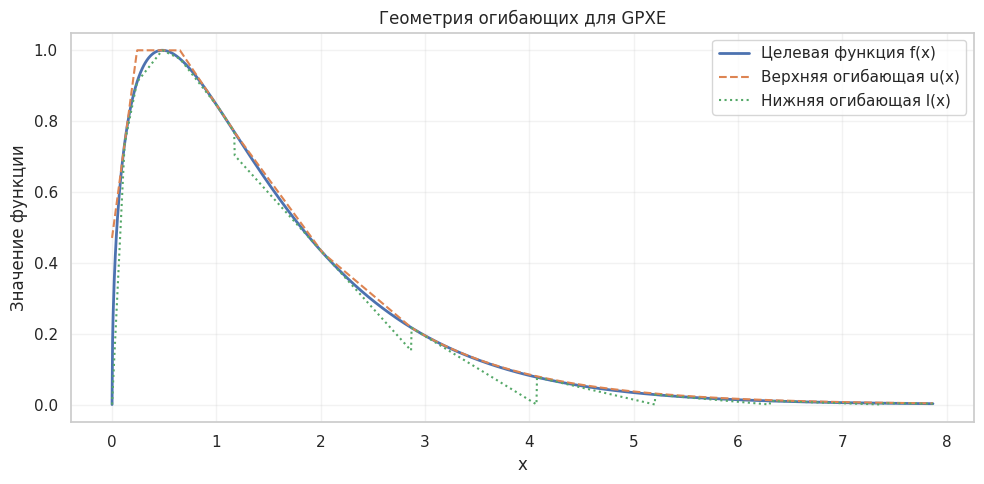

In [ ]:
def gp_upper(x):
    """Верхняя огибающая u(x) для выбранной ветви GPXE."""
    if x < a8:
        return float(gp_tangent(a7, x))

    if x < a9:
        return 1.0

    if x < x4:
        return float(gp_tangent(a10, x))

    if x < a11:
        return f_x4 + (f_a11 - f_x4) * (x - x4) / w7

    if x < x5:
        return f_a11 + (f_x5 - f_a11) * (x - a11) / w8

    # Экспоненциальная огибающая правого хвоста.
    return f_x5 * np.exp(-tail_rate * (x - x5))


# Продолжаем последовательность точек пересечения касательных
# с осью x: x5, x6, x7, x8, x9, x10.
# Формула следует из условия, что касательная в x_i
# пересекает ось x в точке x_{i+1}.
tail_points = [float(x5)]

for _ in range(5):
    p = tail_points[-1]
    tail_points.append(p * (1.0 + 1.0 / (p - x3)))


def gp_lower(x):
    """Нижняя огибающая l(x) по схеме Sarkar (1996)."""

    knots = np.array([x2, a7, a8, x3, a9, a10, x4])
    heights = np.array([gp_f(t) for t in knots], dtype=float)

    # Центральная часть: отрезки, соединяющие значения f
    # в соседних геометрических точках.
    if x < x4:
        i = np.searchsorted(knots, x, side='right') - 1
        i = max(0, min(i, len(knots) - 2))

        xa, xb = knots[i], knots[i + 1]
        ya, yb = heights[i], heights[i + 1]

        return float(ya + (yb - ya) * (x - xa) / (xb - xa))

    # Интервал от x4 до x5: касательная в точке a11.
    if x < x5:
        return float(gp_tangent(a11, x))

    # Правый хвост: отрезки (x_i, f(x_i)) -- (x_{i+1}, 0).
    # Для каждого интервала прямая является касательной
    # в его левой точке.
    for left, right in zip(tail_points[:-1], tail_points[1:]):
        if left <= x < right:
            return float(
                gp_f(left) * (right - x) / (right - left)
            )

    # За последней точкой используем нулевую нижнюю границу.
    return 0.0


# Численная проверка огибающих.
# Границы x4 проверяем с обеих сторон из-за пограничной области.
check_x = np.unique(np.concatenate([
    np.linspace(x2, x4 - 1e-9, 20000),
    np.linspace(x4, x5, 10000),
    np.linspace(x5, x5 + 25.0 / tail_rate, 20000)
]))

upper_violation = min(
    gp_upper(float(x)) - gp_f(x) for x in check_x
)
lower_violation = min(
    gp_f(x) - gp_lower(float(x)) for x in check_x
)

print(f"Минимум u(x) - f(x): {upper_violation:.3e}")
print(f"Минимум f(x) - l(x): {lower_violation:.3e}")

if upper_violation < -1e-9 or lower_violation < -1e-9:
    raise AssertionError(
        "Проверка огибающих не пройдена. Генератор нельзя запускать."
    )

print("Численная проверка огибающих пройдена.")


# Визуальная проверка.
plot_x = np.linspace(0.0, x5 + 5.0, 1500)

f_values = np.array([gp_f(x) for x in plot_x])
u_values = np.array([gp_upper(float(x)) for x in plot_x])
l_values = np.array([gp_lower(float(x)) for x in plot_x])

plt.figure(figsize=(10, 5))
plt.plot(plot_x, f_values, label='Целевая функция f(x)', linewidth=2)
plt.plot(plot_x, u_values, '--', label='Верхняя огибающая u(x)')
plt.plot(plot_x, l_values, ':', label='Нижняя огибающая l(x)')
plt.xlabel('x')
plt.ylabel('Значение функции')
plt.title('Геометрия огибающих для GPXE')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 8.7. Площади областей и таблица псевдонимов

Область под верхней огибающей разбивается на 18 геометрических частей. Для каждой части вычисляем площадь, после чего делим её на суммарную площадь огибающей. Полученные вероятности определяют, как часто должна выбираться каждая область.
Нам нужно научиться случайно выбирать индекс $j$ от 1 до 18 так, чтобы вероятность каждого индекса была именно такой.
Для эффективного выбора области строим таблицу псевдонимов по методу Kronmal–Peterson (1979).

В ней для каждого индекса хранятся порог \(g(j)\) и альтернативный индекс \(a(j)\).

При каждом выборе генерируем два равномерных числа: первое определяет индекс столбца, второе — выбрать этот индекс или его псевдоним. Выбор выполняется за $O(1)$ операций, их число не растет с увелечением количества областей.

*Примечание* альтернативный способ - последовательный перебор, плох тем, что есть вероятность, что нужно будет перебирать все области, что тем хуже, чем больше у нас областей.

In [ ]:
# 18 компонент разбиения площади под верхней огибающей.
# Каждый компонент — прямоугольник, треугольник, параллелограмм или экспоненциальный хвост.

region_names = [
    'R01: левая пограничная область',
    'R02: треугольник под левой огибающей',
    'R03: прямоугольник [a7, a8]',
    'R04: треугольник [a7, a8]',
    'R05: нижний прямоугольник [a8, x3]',
    'R06: верхний прямоугольник [a8, x3]',
    'R07: нижний прямоугольник [x3, a9]',
    'R08: верхний прямоугольник [x3, a9]',
    'R09: нижний прямоугольник [a9, a10]',
    'R10: треугольник [a9, a10]',
    'R11: правая пограничная область',
    'R12: нижний прямоугольник [a10, x4]',
    'R13: треугольник [a10, x4]',
    'R14: нижний прямоугольник [x4, a11]',
    'R15: треугольник [x4, a11]',
    'R16: нижний прямоугольник [a11, x5]',
    'R17: треугольник [a11, x5]',
    'R18: экспоненциальный правый хвост'
]

region_areas = np.array([
    w1 * y5,
    w1 * (f_a7 - y5) / 2.0,

    w2 * f_a7,
    w2 * (1.0 - f_a7) / 2.0,

    w3 * f_a8,
    w3 * (1.0 - f_a8),

    w4 * f_a9,
    w4 * (1.0 - f_a9),

    w5 * f_a10,
    w5 * (1.0 - f_a10) / 2.0,

    w6 * right_gap,
    w6 * f_x4,
    w6 * (f_a10 - right_gap - f_x4) / 2.0,

    w7 * f_a11,
    w7 * (f_x4 - f_a11) / 2.0,

    w8 * f_x5,
    w8 * (f_a11 - f_x5) / 2.0,

    f_x5 / tail_rate
], dtype=float)

n_regions = len(region_areas)

if n_regions != 18:
    raise AssertionError("Ожидалось 18 областей.")

if np.any(~np.isfinite(region_areas)) or np.any(region_areas <= 0):
    raise AssertionError(
        "Некорректная площадь области. Проверь геометрию."
    )

upper_area = float(region_areas.sum())

region_table = pd.DataFrame({
    'Область': region_names,
    'Площадь': region_areas,
    'Вероятность выбора': region_areas / upper_area
})

display(region_table.round(8))

print(f"Число областей: {n_regions}")
print(f"Общая площадь верхней огибающей: {upper_area:.8f}")


# Построение таблицы псевдонимов Kronmal–Peterson.
def build_alias_table(weights):
    weights = np.asarray(weights, dtype=float)

    if (
        weights.ndim != 1
        or len(weights) == 0
        or np.any(~np.isfinite(weights))
        or np.any(weights <= 0)
    ):
        raise ValueError("Площади должны быть конечными и положительными.")

    probabilities = weights / weights.sum()
    n = len(probabilities)

    # Масштабированные вероятности .
    scaled = n * probabilities

    small = [
        i for i, value in enumerate(scaled) if value < 1.0
    ]
    large = [
        i for i, value in enumerate(scaled) if value >= 1.0
    ]

    cutoff = np.ones(n, dtype=float)
    alias_index = np.arange(n, dtype=int)

    while small and large:
        j = small.pop()
        k = large.pop()

        cutoff[j] = scaled[j]
        alias_index[j] = k

        scaled[k] -= 1.0 - scaled[j]

        if scaled[k] < 1.0:
            small.append(k)
        else:
            large.append(k)

    # Оставшиеся элементы имеют порог 1.
    for i in small + large:
        cutoff[i] = 1.0
        alias_index[i] = i

    return cutoff, alias_index, probabilities


alias_cutoff, alias_index, region_probabilities = (
    build_alias_table(region_areas)
)


# Проверяем, что таблица воспроизводит исходные вероятности.
alias_probabilities_check = np.zeros(n_regions)

for i in range(n_regions):
    alias_probabilities_check[i] += alias_cutoff[i] / n_regions
    alias_probabilities_check[alias_index[i]] += (
        1.0 - alias_cutoff[i]
    ) / n_regions

alias_error = np.max(
    np.abs(alias_probabilities_check - region_probabilities)
)

print(f"Максимальная ошибка таблицы псевдонимов: {alias_error:.3e}")

if not np.allclose(
    alias_probabilities_check,
    region_probabilities,
    rtol=1e-12,
    atol=1e-12
):
    raise AssertionError(
        "Таблица псевдонимов не воспроизводит заданные вероятности."
    )

region_table['Порог g(j)'] = alias_cutoff
region_table['Псевдоним a(j)'] = alias_index + 1

display(region_table.round(8))

,Область,Площадь,Вероятность выбора
0,R01: левая пограничная область,0.056609,0.027074
1,R02: треугольник под левой огибающей,0.015994,0.007649
2,"R03: прямоугольник [a7, a8]",0.087949,0.042062
3,"R04: треугольник [a7, a8]",0.015761,0.007538
4,"R05: нижний прямоугольник [a8, x3]",0.219939,0.105187
5,"R06: верхний прямоугольник [a8, x3]",0.021645,0.010352
6,"R07: нижний прямоугольник [x3, a9]",0.165095,0.078958
7,"R08: верхний прямоугольник [x3, a9]",0.004042,0.001933
8,"R09: нижний прямоугольник [a9, a10]",0.297043,0.142063
9,"R10: треугольник [a9, a10]",0.027098,0.012960


Число областей: 18
Общая площадь верхней огибающей: 2.09092650
Максимальная ошибка таблицы псевдонимов: 6.939e-17


,Область,Площадь,Вероятность выбора,Порог g(j),Псевдоним a(j)
0,R01: левая пограничная область,0.056609,0.027074,0.487324,5
1,R02: треугольник под левой огибающей,0.015994,0.007649,0.137688,9
2,"R03: прямоугольник [a7, a8]",0.087949,0.042062,0.757117,9
3,"R04: треугольник [a7, a8]",0.015761,0.007538,0.135680,9
4,"R05: нижний прямоугольник [a8, x3]",0.219939,0.105187,1.000000,5
5,"R06: верхний прямоугольник [a8, x3]",0.021645,0.010352,0.186333,14
6,"R07: нижний прямоугольник [x3, a9]",0.165095,0.078958,0.619301,5
7,"R08: верхний прямоугольник [x3, a9]",0.004042,0.001933,0.034795,14
8,"R09: нижний прямоугольник [a9, a10]",0.297043,0.142063,0.198063,7
9,"R10: треугольник [a9, a10]",0.027098,0.012960,0.233276,14


### 8.8. Реализация генератора GPXE

На каждом испытании с помощью таблицы псевдонимов выбираем геометрическую область. Затем генерируем точку внутри неё с использованием независимых равномерных случайных величин.

Сначала выполняется предварительная проверка по нижней огибающей. Если она не позволяет принять кандидата, выполняется полная проверка по целевой функции $f(x)$. Кандидаты, не прошедшие полную проверку, отбрасываются.

После принятия переводим результат в исходный масштаб остаточного сахара с помощью преобразования $Y=\theta X$. Эксперимент будет воспроизводим благодаря тому что мы фиксируем seed

In [ ]:
def sample_gpxe_region(j, u, v):
    """
    Равномерная точка (x, y) внутри выбранной области j.
    j — индекс от 0 до 17.
    u, v — независимые U(0, 1).
    """
    u = float(np.clip(u, 0.0, np.nextafter(1.0, 0.0)))
    v = float(np.clip(v, 0.0, np.nextafter(1.0, 0.0)))

    if j == 0:
        # Левая пограничная параллелограммная область.
        x = x2 + w1 * u
        top = float(gp_tangent(a7, x))
        y = (top - y5) + v * y5

    elif j == 1:
        # Треугольник под сдвинутой левой касательной.
        x = x2 + w1 * np.sqrt(u)
        top = float(gp_tangent(a7, x)) - y5
        y = v * top

    elif j == 2:
        x = a7 + w2 * u
        y = v * f_a7

    elif j == 3:
        # Треугольник с высотой, возрастающей слева направо.
        x = a7 + w2 * np.sqrt(u)
        top = float(gp_tangent(a7, x))
        y = f_a7 + v * (top - f_a7)

    elif j == 4:
        x = a8 + w3 * u
        y = v * f_a8

    elif j == 5:
        x = a8 + w3 * u
        y = f_a8 + v * (1.0 - f_a8)

    elif j == 6:
        x = x3 + w4 * u
        y = v * f_a9

    elif j == 7:
        x = x3 + w4 * u
        y = f_a9 + v * (1.0 - f_a9)

    elif j == 8:
        x = a9 + w5 * u
        y = v * f_a10

    elif j == 9:
        # Треугольник с высотой, убывающей слева направо.
        x = a9 + w5 * (1.0 - np.sqrt(1.0 - u))
        top = float(gp_tangent(a10, x))
        y = f_a10 + v * (top - f_a10)

    elif j == 10:
        # Правая пограничная параллелограммная область.
        x = a10 + w6 * u
        top = float(gp_tangent(a10, x))
        y = (top - right_gap) + v * right_gap

    elif j == 11:
        x = a10 + w6 * u
        y = v * f_x4

    elif j == 12:
        x = a10 + w6 * (1.0 - np.sqrt(1.0 - u))
        top = float(gp_tangent(a10, x)) - right_gap
        y = f_x4 + v * (top - f_x4)

    elif j == 13:
        x = x4 + w7 * u
        y = v * f_a11

    elif j == 14:
        x = x4 + w7 * (1.0 - np.sqrt(1.0 - u))
        top = f_x4 + (f_a11 - f_x4) * (x - x4) / w7
        y = f_a11 + v * (top - f_a11)

    elif j == 15:
        x = a11 + w8 * u
        y = v * f_x5

    elif j == 16:
        x = a11 + w8 * (1.0 - np.sqrt(1.0 - u))
        top = f_a11 + (f_x5 - f_a11) * (x - a11) / w8
        y = f_x5 + v * (top - f_x5)

    elif j == 17:
        # Правый экспоненциальный хвост.
        x = x5 - np.log1p(-u) / tail_rate
        top = f_x5 * np.exp(-tail_rate * (x - x5))
        y = v * top

    else:
        raise IndexError("Номер области вне диапазона 0–17.")

    return float(x), float(y)


def generate_gpxe(n, seed=2026):
    """
    Генерирует n значений остаточного сахара
    методом композиции–alias с огибающими GPXE.
    """
    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError("n должен быть положительным целым числом.")

    rng = np.random.default_rng(seed)
    generated = np.empty(n, dtype=float)

    accepted = 0
    attempts = 0
    accepted_by_squeeze = 0
    accepted_by_full_test = 0
    rejected = 0

    while accepted < n:
        # Выбор области по схеме Sarkar с одной U(0, 1).
        u0 = float(rng.random())

        # Исключаем точное нулевое значение из-за особенностей PRNG.
        if u0 == 0.0:
            u0 = 2.0 ** -53

        k = int(n_regions * u0)
        v0 = (k + 1) - n_regions * u0

        if v0 < alias_cutoff[k]:
            j = k
            u_region = v0 / alias_cutoff[k]
        else:
            j = int(alias_index[k])
            u_region = (
                (v0 - alias_cutoff[k]) /
                (1.0 - alias_cutoff[k])
            )

        u_region = float(np.clip(
            u_region, 0.0, np.nextafter(1.0, 0.0)
        ))

        # Вторая независимая равномерная величина.
        v_region = float(rng.random())

        x, y = sample_gpxe_region(j, u_region, v_region)
        attempts += 1

        # Pretest: нижняя огибающая.
        if y <= gp_lower(x):
            generated[accepted] = gamma_scale * x
            accepted += 1
            accepted_by_squeeze += 1

        else:
            # Full test: исходная целевая функция.
            if y <= gp_f(x):
                generated[accepted] = gamma_scale * x
                accepted += 1
                accepted_by_full_test += 1
            else:
                rejected += 1

    info = {
        'сгенерировано значений': n,
        'число испытаний': attempts,
        'принято по pretest': accepted_by_squeeze,
        'принято по full test': accepted_by_full_test,
        'отбраковано': rejected,
        'доля принятых кандидатов': n / attempts,
        'доля значений, принятых по pretest': (
            accepted_by_squeeze / n
        )
    }

    return generated, info

### 8.9. Сравнение статистик

Генерируем 50 000 значений и сравниваем три набора характеристик: исходные данные, сгенерированную выборку и теоретическое гамма-распределение с выбранными параметрами.

Рассматриваем среднее, дисперсию, медиану и несколько квантилей. Сравнение генератора с теоретической моделью позволяет проверить реализацию алгоритма, а сравнение с исходными данными показывает, насколько выбранная модель описывает эмпирическую совокупность.
В блоке 8.11 будет проведено уже сравнение и анализ метрик.

In [ ]:
N_GENERATED = 50_000

generated_residual_sugar, generation_info = generate_gpxe(
    N_GENERATED,
    seed=20261023
)

display(pd.Series(generation_info, name='Результат'))

# Исходные наблюдения.
real_x = population['residual sugar'].to_numpy(dtype=float)

# Теоретические характеристики выбранной гамма-модели.
theoretical_mean = gamma_shape * gamma_scale
theoretical_variance = gamma_shape * gamma_scale**2

metric_names = [
    'Среднее',
    'Дисперсия (ddof=0)',
    'Медиана',
    'Квантиль 0.25',
    'Квантиль 0.75',
    'Квантиль 0.95'
]

def calculate_metrics(x):
    return [
        np.mean(x),
        np.var(x, ddof=0),
        np.median(x),
        np.quantile(x, 0.25),
        np.quantile(x, 0.75),
        np.quantile(x, 0.95)
    ]

theoretical_metrics = [
    theoretical_mean,
    theoretical_variance,
    float(stats.gamma.ppf(
        0.50, a=gamma_shape, loc=0, scale=gamma_scale
    )),
    float(stats.gamma.ppf(
        0.25, a=gamma_shape, loc=0, scale=gamma_scale
    )),
    float(stats.gamma.ppf(
        0.75, a=gamma_shape, loc=0, scale=gamma_scale
    )),
    float(stats.gamma.ppf(
        0.95, a=gamma_shape, loc=0, scale=gamma_scale
    ))
]

comparison_table = pd.DataFrame({
    'Показатель': metric_names,
    'Исходные данные': calculate_metrics(real_x),
    'GPXE': calculate_metrics(generated_residual_sugar),
    'Теоретическая гамма-модель': theoretical_metrics
}).set_index('Показатель')

display(comparison_table.round(4))

,Результат
сгенерировано значений,50000.000000
число испытаний,51336.000000
принято по pretest,47196.000000
принято по full test,2804.000000
отбраковано,1336.000000
доля принятых кандидатов,0.973975
"доля значений, принятых по pretest",0.943920


,Исходные данные,GPXE,Теоретическая гамма-модель
Показатель,,,
Среднее,6.3914,6.4276,6.3914
Дисперсия (ddof=0),25.7205,28.1858,27.5753
Медиана,5.2000,5.0563,5.0247
Квантиль 0.25,1.7000,2.5727,2.5611
Квантиль 0.75,9.9000,8.7882,8.7581
Квантиль 0.95,15.7000,16.7604,16.7187


In [ ]:
# наглядное сравнение метрик
metric_check = comparison_table.copy()

metric_check['Δ GPXE − исходные'] = (
    comparison_table['GPXE']
    - comparison_table['Исходные данные']
)

metric_check['Отклонение GPXE от исходных, %'] = (
    100
    * metric_check['Δ GPXE − исходные']
    / comparison_table['Исходные данные']
)

metric_check['Δ GPXE − теория'] = (
    comparison_table['GPXE']
    - comparison_table['Теоретическая гамма-модель']
)

metric_check['Отклонение GPXE от теории, %'] = (
    100
    * metric_check['Δ GPXE − теория']
    / comparison_table['Теоретическая гамма-модель']
)

display(metric_check.round(4))

,Исходные данные,GPXE,Теоретическая гамма-модель,Δ GPXE − исходные,"Отклонение GPXE от исходных, %",Δ GPXE − теория,"Отклонение GPXE от теории, %"
Показатель,,,,,,,
Среднее,6.3914,6.4276,6.3914,0.0362,0.5657,0.0362,0.5657
Дисперсия (ddof=0),25.7205,28.1858,27.5753,2.4653,9.5850,0.6106,2.2142
Медиана,5.2000,5.0563,5.0247,-0.1437,-2.7639,0.0315,0.6279
Квантиль 0.25,1.7000,2.5727,2.5611,0.8727,51.3332,0.0115,0.4496
Квантиль 0.75,9.9000,8.7882,8.7581,-1.1118,-11.2299,0.0301,0.3440
Квантиль 0.95,15.7000,16.7604,16.7187,1.0604,6.7541,0.0416,0.2491


### 8.10. Графическая и статистическая проверка генератора

Построим график сравнивающий плотности исходных данных, сгенерированной выборки и теоретического гамма-распределения. Линейная шкала не позволяет хорошо рассмотреть поведение наших данных для малых значений `residual sugar`, однако она довольно показательна для сравнения области пика исходных данных, сгенерированных и теоретических, а также рассмотрения правого хвоста. Логарифмическая шкала по оси $x$ позволяет лучше рассмотреть малые значения остаточного сахара, поэтому ее также добавим для большей наглядности результатов.

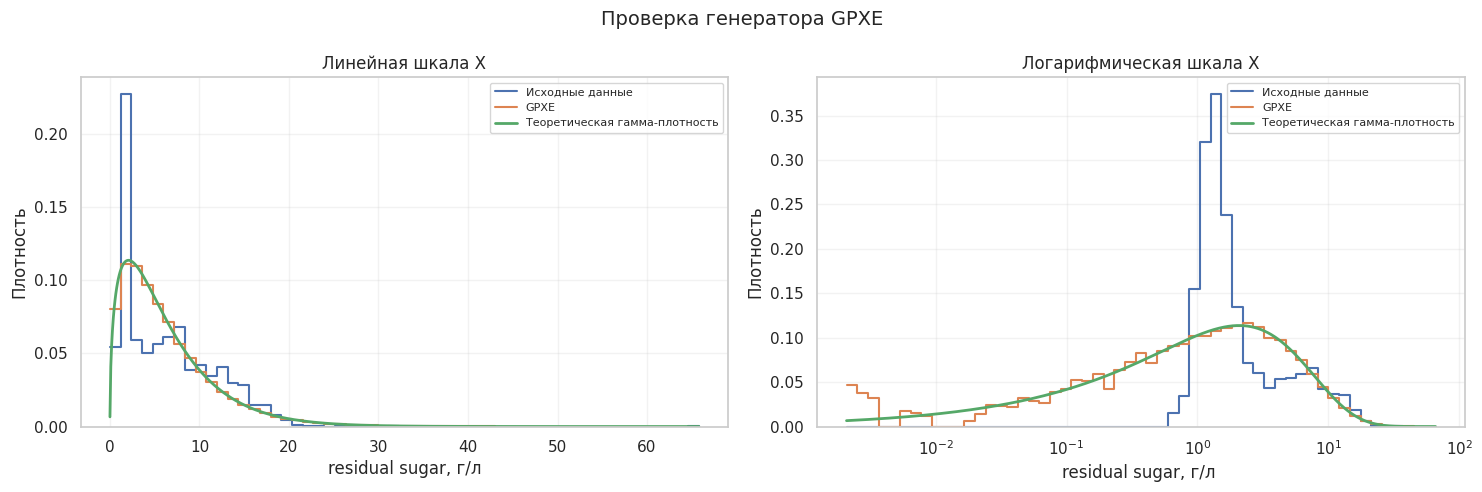

In [ ]:
import seaborn as sns
# Общий диапазон для обоих графиков
xmin = min(real_x.min(), generated_residual_sugar.min())
xmax = max(real_x.max(), generated_residual_sugar.max())

# Линейные интервалы — для обычного графика
bins_linear = np.linspace(xmin, xmax, 56)
grid_linear = np.linspace(xmin, xmax, 700)
xmin_log = max(xmin, np.finfo(float).tiny)
bins_log = np.geomspace(xmin_log, xmax, 56)
grid_log = np.geomspace(xmin_log, xmax, 700)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

#  Линейная ось X
ax = axes[0]

sns.histplot(
    real_x,
    bins=bins_linear,
    stat='density',
    element='step',
    fill=False,
    linewidth=1.5,
    label='Исходные данные',
    ax=ax
)

sns.histplot(
    generated_residual_sugar,
    bins=bins_linear,
    stat='density',
    element='step',
    fill=False,
    linewidth=1.5,
    label='GPXE',
    ax=ax
)

ax.plot(
    grid_linear,
    stats.gamma.pdf(
        grid_linear,
        a=gamma_shape,
        loc=0,
        scale=gamma_scale
    ),
    linewidth=2,
    label='Теоретическая гамма-плотность'
)

ax.set_xlabel('residual sugar, г/л')
ax.set_ylabel('Плотность')
ax.set_title('Линейная шкала X')
ax.legend(fontsize=8)
ax.grid(alpha=0.25)


# Логарифмическая ось X

ax = axes[1]

sns.histplot(
    real_x,
    bins=bins_log,
    stat='density',
    element='step',
    fill=False,
    linewidth=1.5,
    label='Исходные данные',
    ax=ax
)

sns.histplot(
    generated_residual_sugar,
    bins=bins_log,
    stat='density',
    element='step',
    fill=False,
    linewidth=1.5,
    label='GPXE',
    ax=ax
)

ax.plot(
    grid_log,
    stats.gamma.pdf(
        grid_log,
        a=gamma_shape,
        loc=0,
        scale=gamma_scale
    ),
    linewidth=2,
    label='Теоретическая гамма-плотность'
)

ax.set_xscale('log')
ax.set_xlabel('residual sugar, г/л ')
ax.set_ylabel('Плотность')
ax.set_title('Логарифмическая шкала X')
ax.legend(fontsize=8)
ax.grid(alpha=0.25)

fig.suptitle('Проверка генератора GPXE', fontsize=14)
plt.tight_layout()
plt.show()




### 8.11. Сравнение метрик, выводы

Среднее сгенерированной выборки равно 6,4276 против теоретического значения 6,3914; дисперсия — 28,1858 против 27,5753. Различия составляют приблизительно 0,57% для среднего и 2,21% для дисперсии. Медиана и квантили также близки к теоретическим значениям: относительные отклонения составляют около 0,63% для медианы, 0,45% для 25-го процентиля, 0,34% для 75-го процентиля и 0,25% для 95-го процентиля.

Полного совпадения всех метрик не наблюдается, но это не показывает, того, что генератор написан неправильно или плохо. Не совпадение накапливается по двум причинам, во-первых, наш генератор воспроизводит гамма распределение; во-вторых, гамма распределение не идеально описывает наши изначальные данные - оно описывает лучше всех среди рассмотренных нами ранее моделей по BIC. Хоть графически совпадение субъективно невысокое, но полученные данные показывают, что задача выполненна неплохо.

# Источники

1. Cortez, P., Cerdeira, A., Almeida, F., Matos, T. **Modeling wine preferences by data mining from physicochemical properties.** *Decision Support Systems*, 47(4), 547–553, 2009. DOI: [10.1016/j.dss.2009.05.016](https://doi.org/10.1016/j.dss.2009.05.016). Исследование использует физико-химические характеристики белых и красных вин Vinho Verde.
2. UCI Machine Learning Repository. **Wine Quality** — описание набора данных и переменных: [страница датасета](https://archive.ics.uci.edu/dataset/186/wine+quality). DOI датасета: [10.24432/C56S3T](https://doi.org/10.24432/C56S3T). Используется как источник данных.
3. SciPy documentation. **`scipy.stats.normaltest`** — описание критерия Д’Агостино — Пирсона и проверяемой нулевой гипотезы: [документация](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.normaltest.html).

4. Sarkar, T. K. (1996). A Composition-Alias Method for Generating Gamma Variates with Shape Parameter Greater than 1. *ACM Transactions on Mathematical Software*, 22(4), 484–492. https://doi.org/10.1145/235815.235822

5. Schmeiser, B. W., Lal, R. (1980). Squeeze Methods for Generating Gamma Variates. *Journal of the American Statistical Association*, 75(371), 679–682. https://doi.org/10.1080/01621459.1980.10477532

6. Kronmal, R. A., Peterson, A. V. (1979). On the Alias Method for Generating Random Variables from a Discrete Distribution. *The American Statistician*, 33(4), 214–218. https://doi.org/10.1080/00031305.1979.10482697


***Примечание***

Оригинальная статья с генератором - четвертая, она является открытой к просмотру на сайте издательства, однако поскольку у нас алгоритм сочетающий три метода, авторы ссылаясь на оригинальные работы, применяют методы описанные у Schmeiser и Kronmal. Эти работы в свою очередь имеют ограниченный платный доступ на сайте издательства, их содержание было труднее найти.
